# Unit 2 Exploratory Data Analysis
Part A completes the EDA tutorial from the Unit 2 brief, the supplied notebook *A Tutorial on Exploratory Data Analysis*, using the Ames house-price data. Part B applies the same steps to the Auto MPG data and answers the five tasks in the brief. The supplied notebook and data files are unchanged; I worked on a copy. The Auto MPG data come from Quinlan (1993) through the UCI repository, under a CC BY 4.0 licence.

This is exploration only. I did not train a prediction model, so there is no test accuracy to report. I opened the house-price test file only to check its columns and gaps, so it did not influence any choice I made. The figures and tables for my report are saved in `Unit2_ePortfolio_Exports`.

In [1]:
from datetime import datetime, timezone
print("Run by Anne Dayer (student 39359) on my computer on",
      datetime.now(timezone.utc).strftime("%d %B %Y at %H:%M UTC"))

Run by Anne Dayer (student 39359) on my computer on 28 October 2026 at 15:03 UTC


In [2]:
import sys, platform, json, hashlib, importlib.util, subprocess
from pathlib import Path
if importlib.util.find_spec('seaborn') is None or importlib.util.find_spec('missingno') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'seaborn==0.13.2', 'missingno==0.5.2', 'matplotlib>=3.8,<3.10', 'pyparsing==3.2.3'])
import numpy as np
import pandas as pd
import scipy
import scipy.stats as st
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
import missingno as msno
from scipy.cluster import hierarchy
from IPython.display import display
required=['train.csv','test.csv','Auto-mpg dataset.csv']
if any(not Path(f).exists() for f in required):
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Run from the Unit2_Seminar folder with all three supplied CSV files.')
    print('Upload all three supplied CSV files now.')
    files.upload()
assert all(Path(f).exists() for f in required), 'One or more required CSV files are missing.'
OUT=Path('Unit2_ePortfolio_Exports'); OUT.mkdir(exist_ok=True)
versions={'Python':platform.python_version(), **{m.__name__:m.__version__ for m in [np,pd,scipy,sns,matplotlib]}}
hashes={f:hashlib.sha256(Path(f).read_bytes()).hexdigest() for f in required}
(OUT/'environment_and_inputs.json').write_text(json.dumps({'versions':versions,'sha256':hashes},indent=2))
print(versions)
sns.set_theme(style='whitegrid',font_scale=1)
plt.rcParams.update({'figure.dpi':100,'savefig.dpi':150})
def save_figures(prefix):
    for j,num in enumerate(plt.get_fignums(),1):
        fig=plt.figure(num)
        fig.savefig(OUT/f'{prefix}_{j:02d}.png',bbox_inches='tight')
        plt.show()
        plt.close(fig)

{'Python': '3.14.9', 'numpy': '2.5.0', 'pandas': '3.1.0', 'scipy': '1.18.1', 'seaborn': '0.13.2', 'matplotlib': '3.11.2'}


## Part A: the EDA tutorial from the brief
Part A follows the EDA tutorial set in the brief, *A Tutorial on Exploratory Data Analysis*. I kept all of its analysis steps and wrote its notes in my own words. Where an old function no longer works in current libraries, I replaced it with the current one.

Two points I noted. Some number columns, such as MSSubClass, are codes for house types, not measurements. In this dataset `NA` often means the house has no such feature, for example no pool, so a gap is not always an unknown value.

### Data used
The data are Ames house prices (De Cock, 2011): 1,460 training rows with a sale price and 1,459 test rows without one. The 80 input columns include Id, so they are not 80 separate measurements. I left out the tutorial's opening paragraph because it gives the wrong number of test rows; it remains in the supplied file.

## Import Libraries

In [3]:
# The libraries were already loaded in the setup cell at the top.

I load the training and test files with the pandas `read_csv()` function and check their sizes.

In [4]:
train=pd.read_csv('train.csv')
test=pd.read_csv('test.csv')
train_raw=train.copy(deep=True); test_raw=test.copy(deep=True)
print('Actual shapes:',train.shape,test.shape)
assert train.shape==(1460,81) and test.shape==(1459,80)
assert 'SalePrice' in train and 'SalePrice' not in test
assert set(train.columns)-{'SalePrice'}==set(test.columns)
assert not set(train.Id).intersection(test.Id)

Actual shapes: (1460, 81) (1459, 80)


`describe()` gives a first summary of each number column: the count, mean, spread and range. It leaves out missing values.

In [5]:
display(train.describe())

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


`head()` and `tail()` show the first and last rows, a quick way to see what the values look like.

In [6]:
display(train.head())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [7]:
display(train.tail())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


In [8]:
display(train.shape , test.shape)

(1460, 81)

(1459, 80)

The numeric columns in the training data.

In [9]:
numeric_features = train.select_dtypes(include=[np.number])

display(numeric_features.columns)

Index(['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='str')

The category columns in the training data.

In [10]:
categorical_features=train.select_dtypes(include=['object','string','category']).copy()
display(categorical_features.columns)

Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',
       'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
       'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition'],
      dtype='str')

Visualising missing values for a sample of 250 

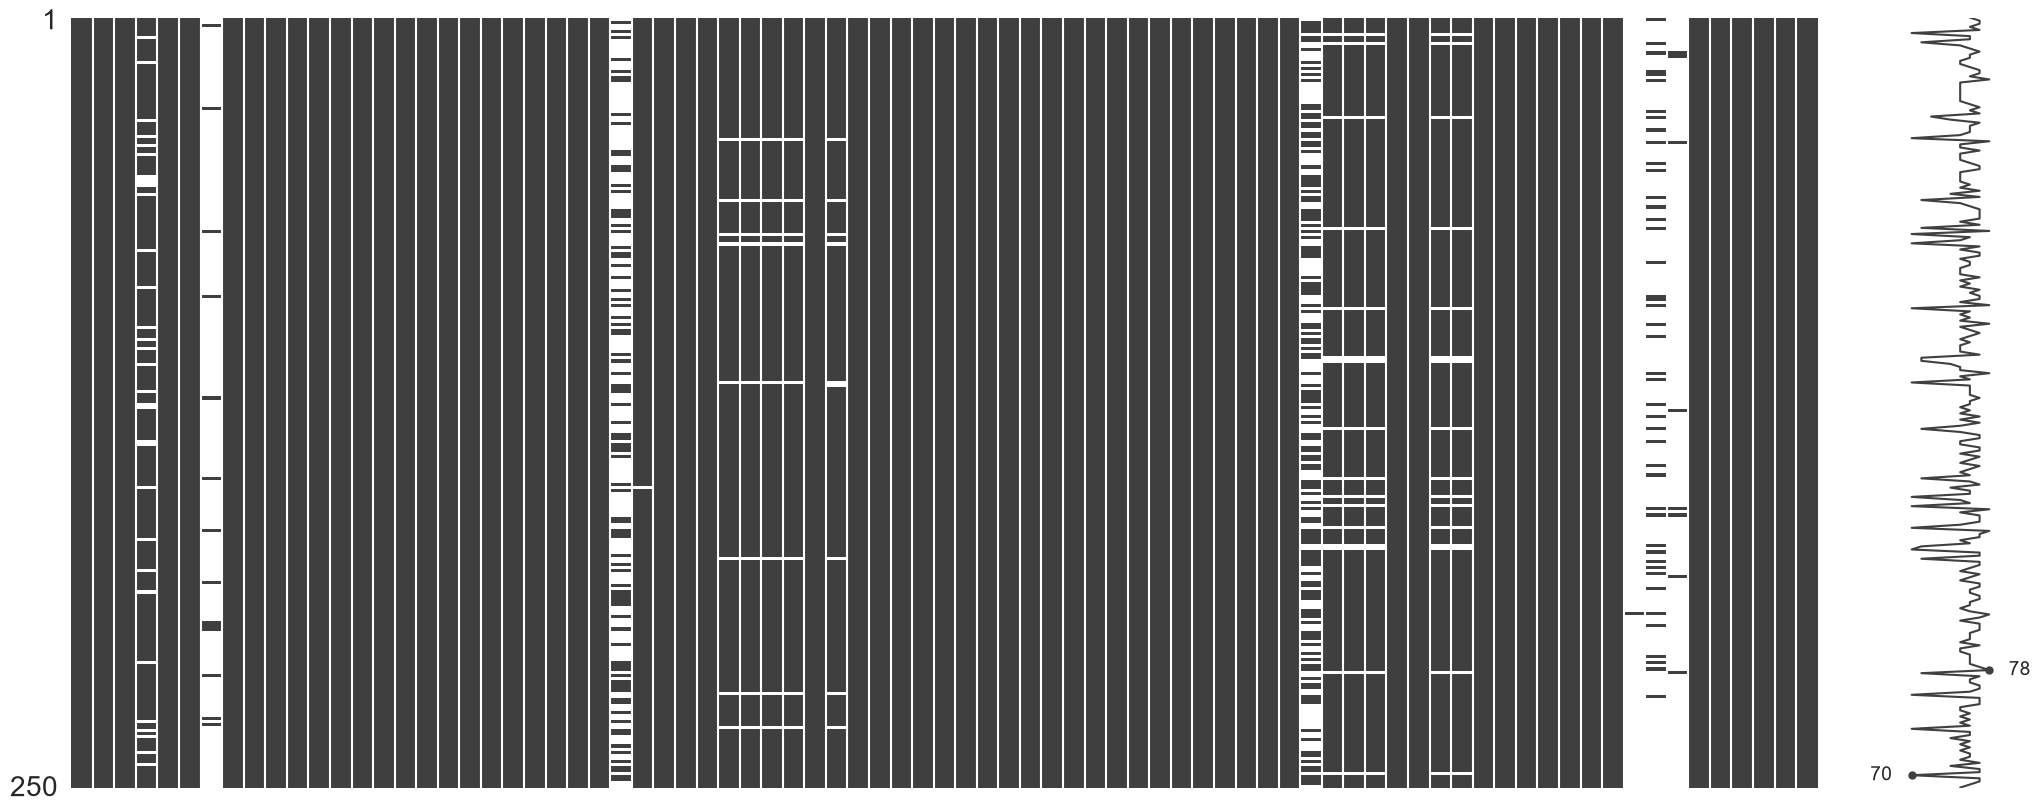

In [11]:
msno.matrix(train.sample(250,random_state=42))
save_figures('house_cell_16')

#### Heatmap
The missingno heatmap shows nullity correlation: how strongly a gap in one column goes with a gap, or a value, in another.

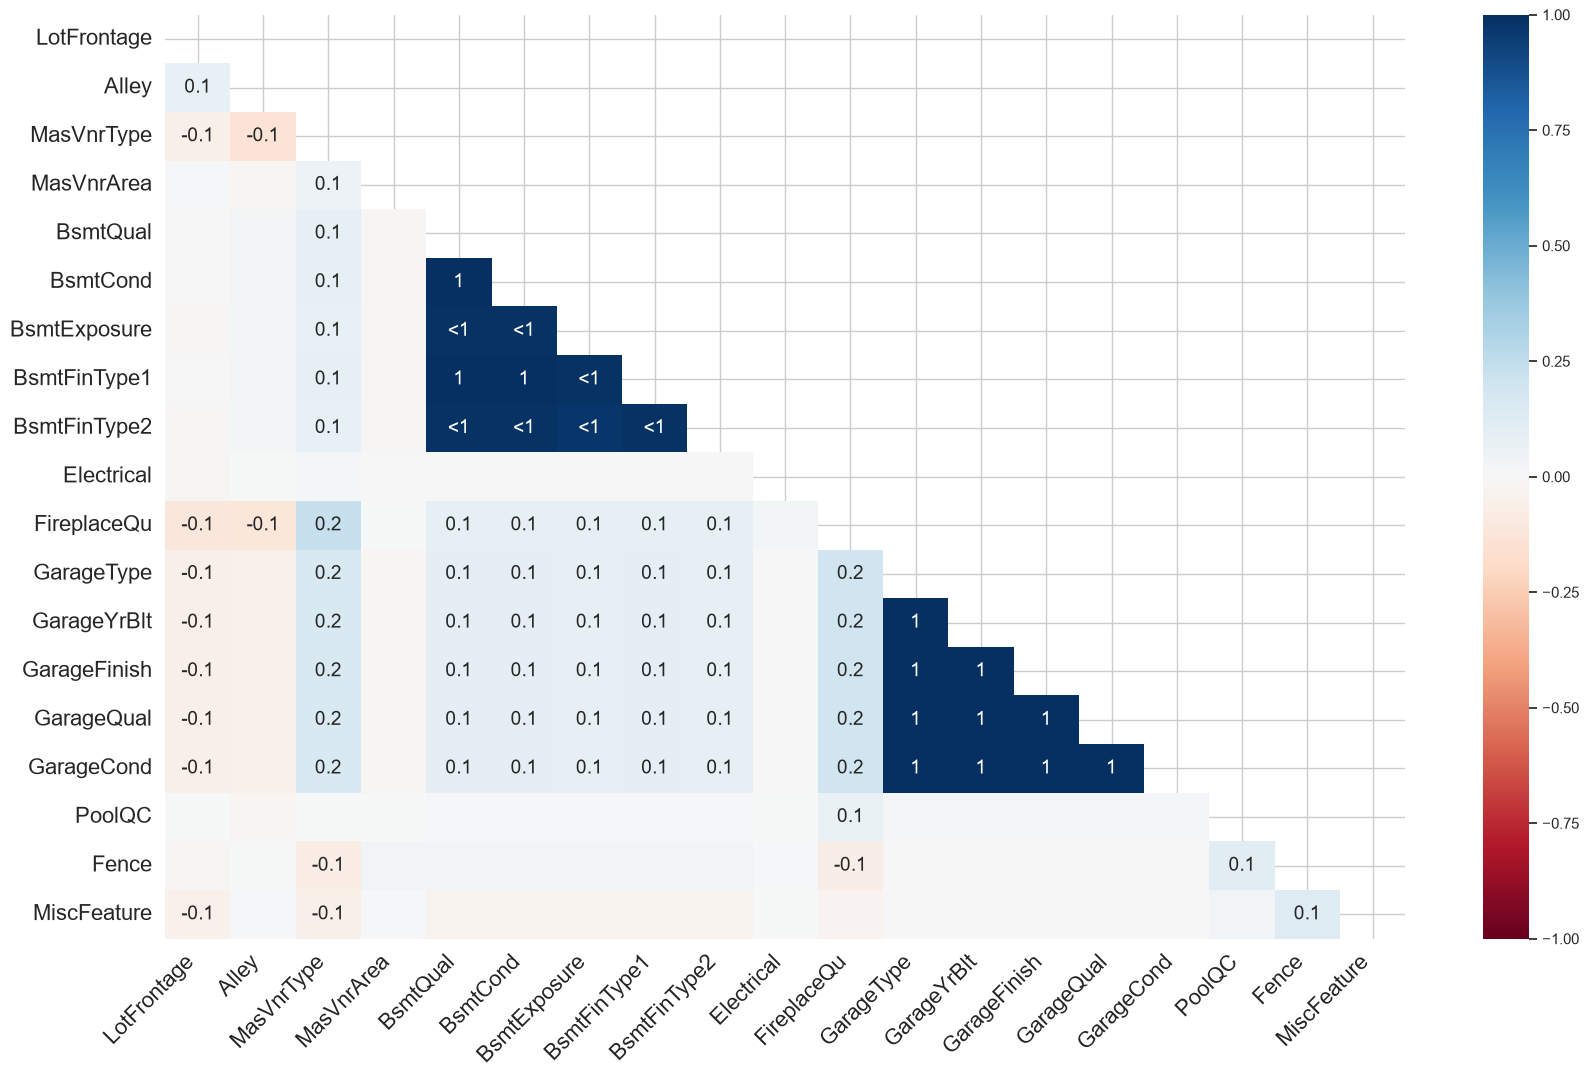

In [12]:
msno.heatmap(train)
save_figures('house_cell_18')

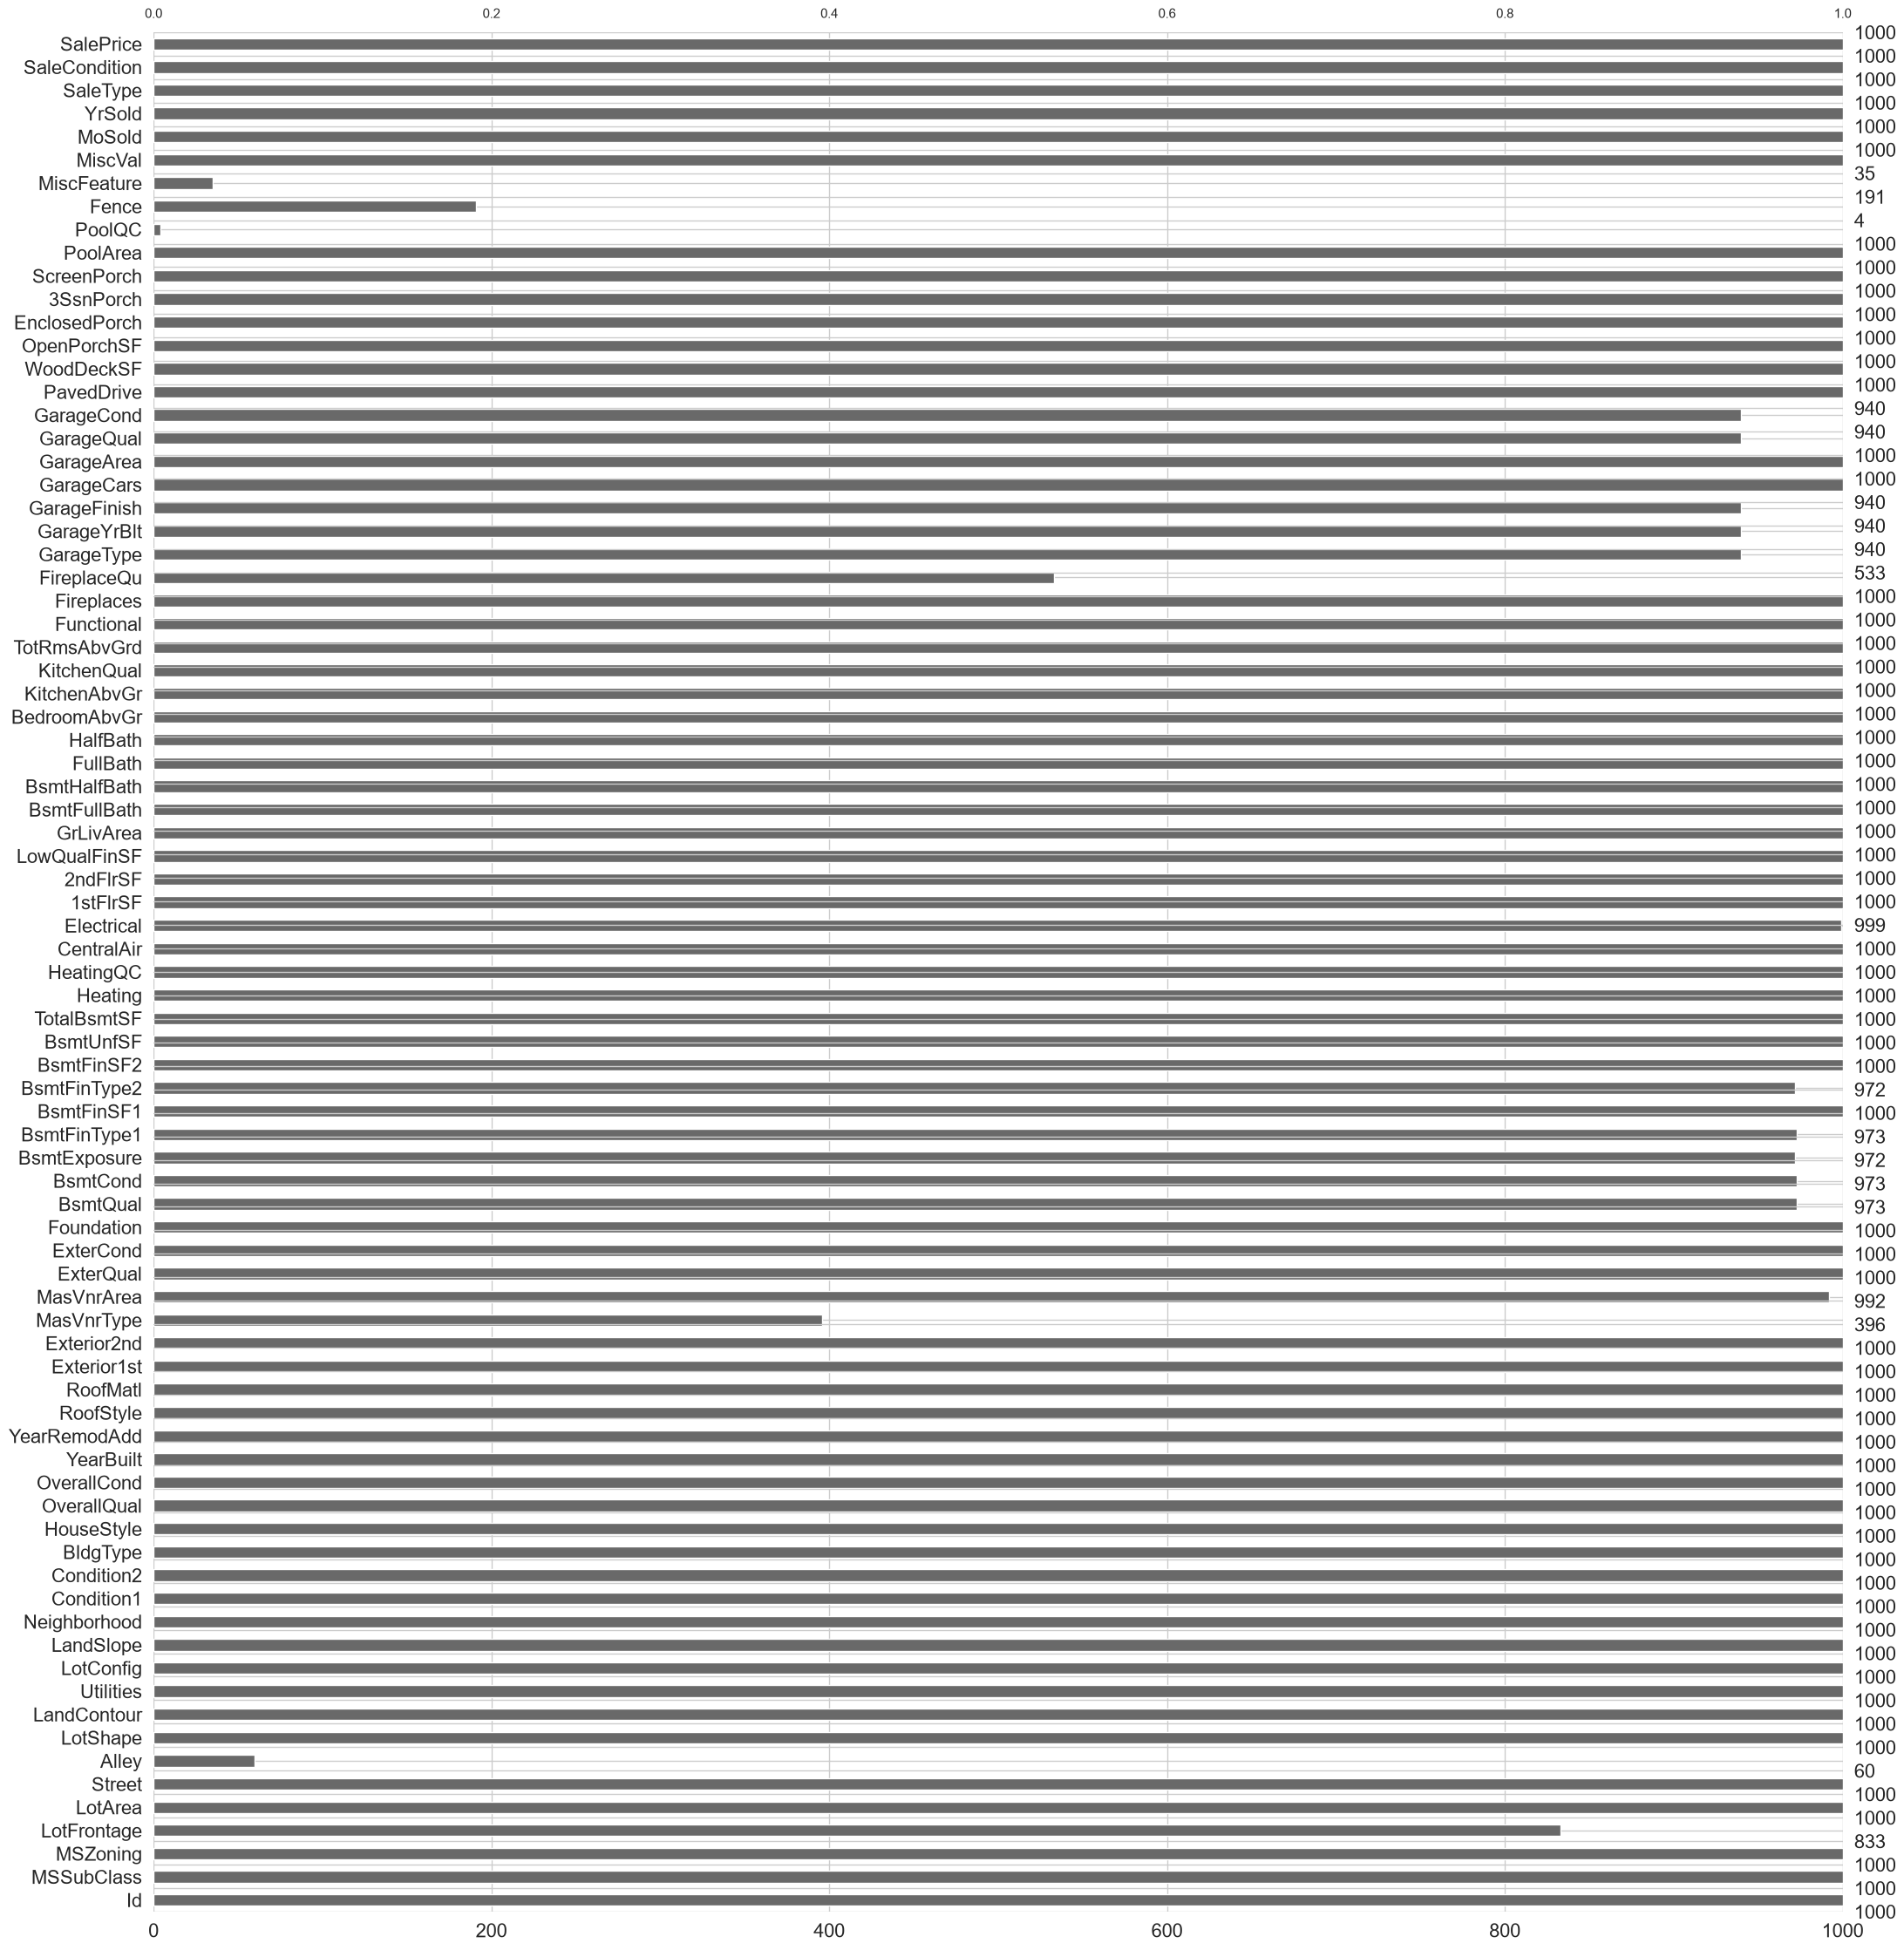

In [13]:
msno.bar(train.sample(1000,random_state=42))
save_figures('house_cell_19')

#### Dendrogram
The dendrogram groups columns by how alike their gaps are, which can show patterns that the pairwise heatmap misses.

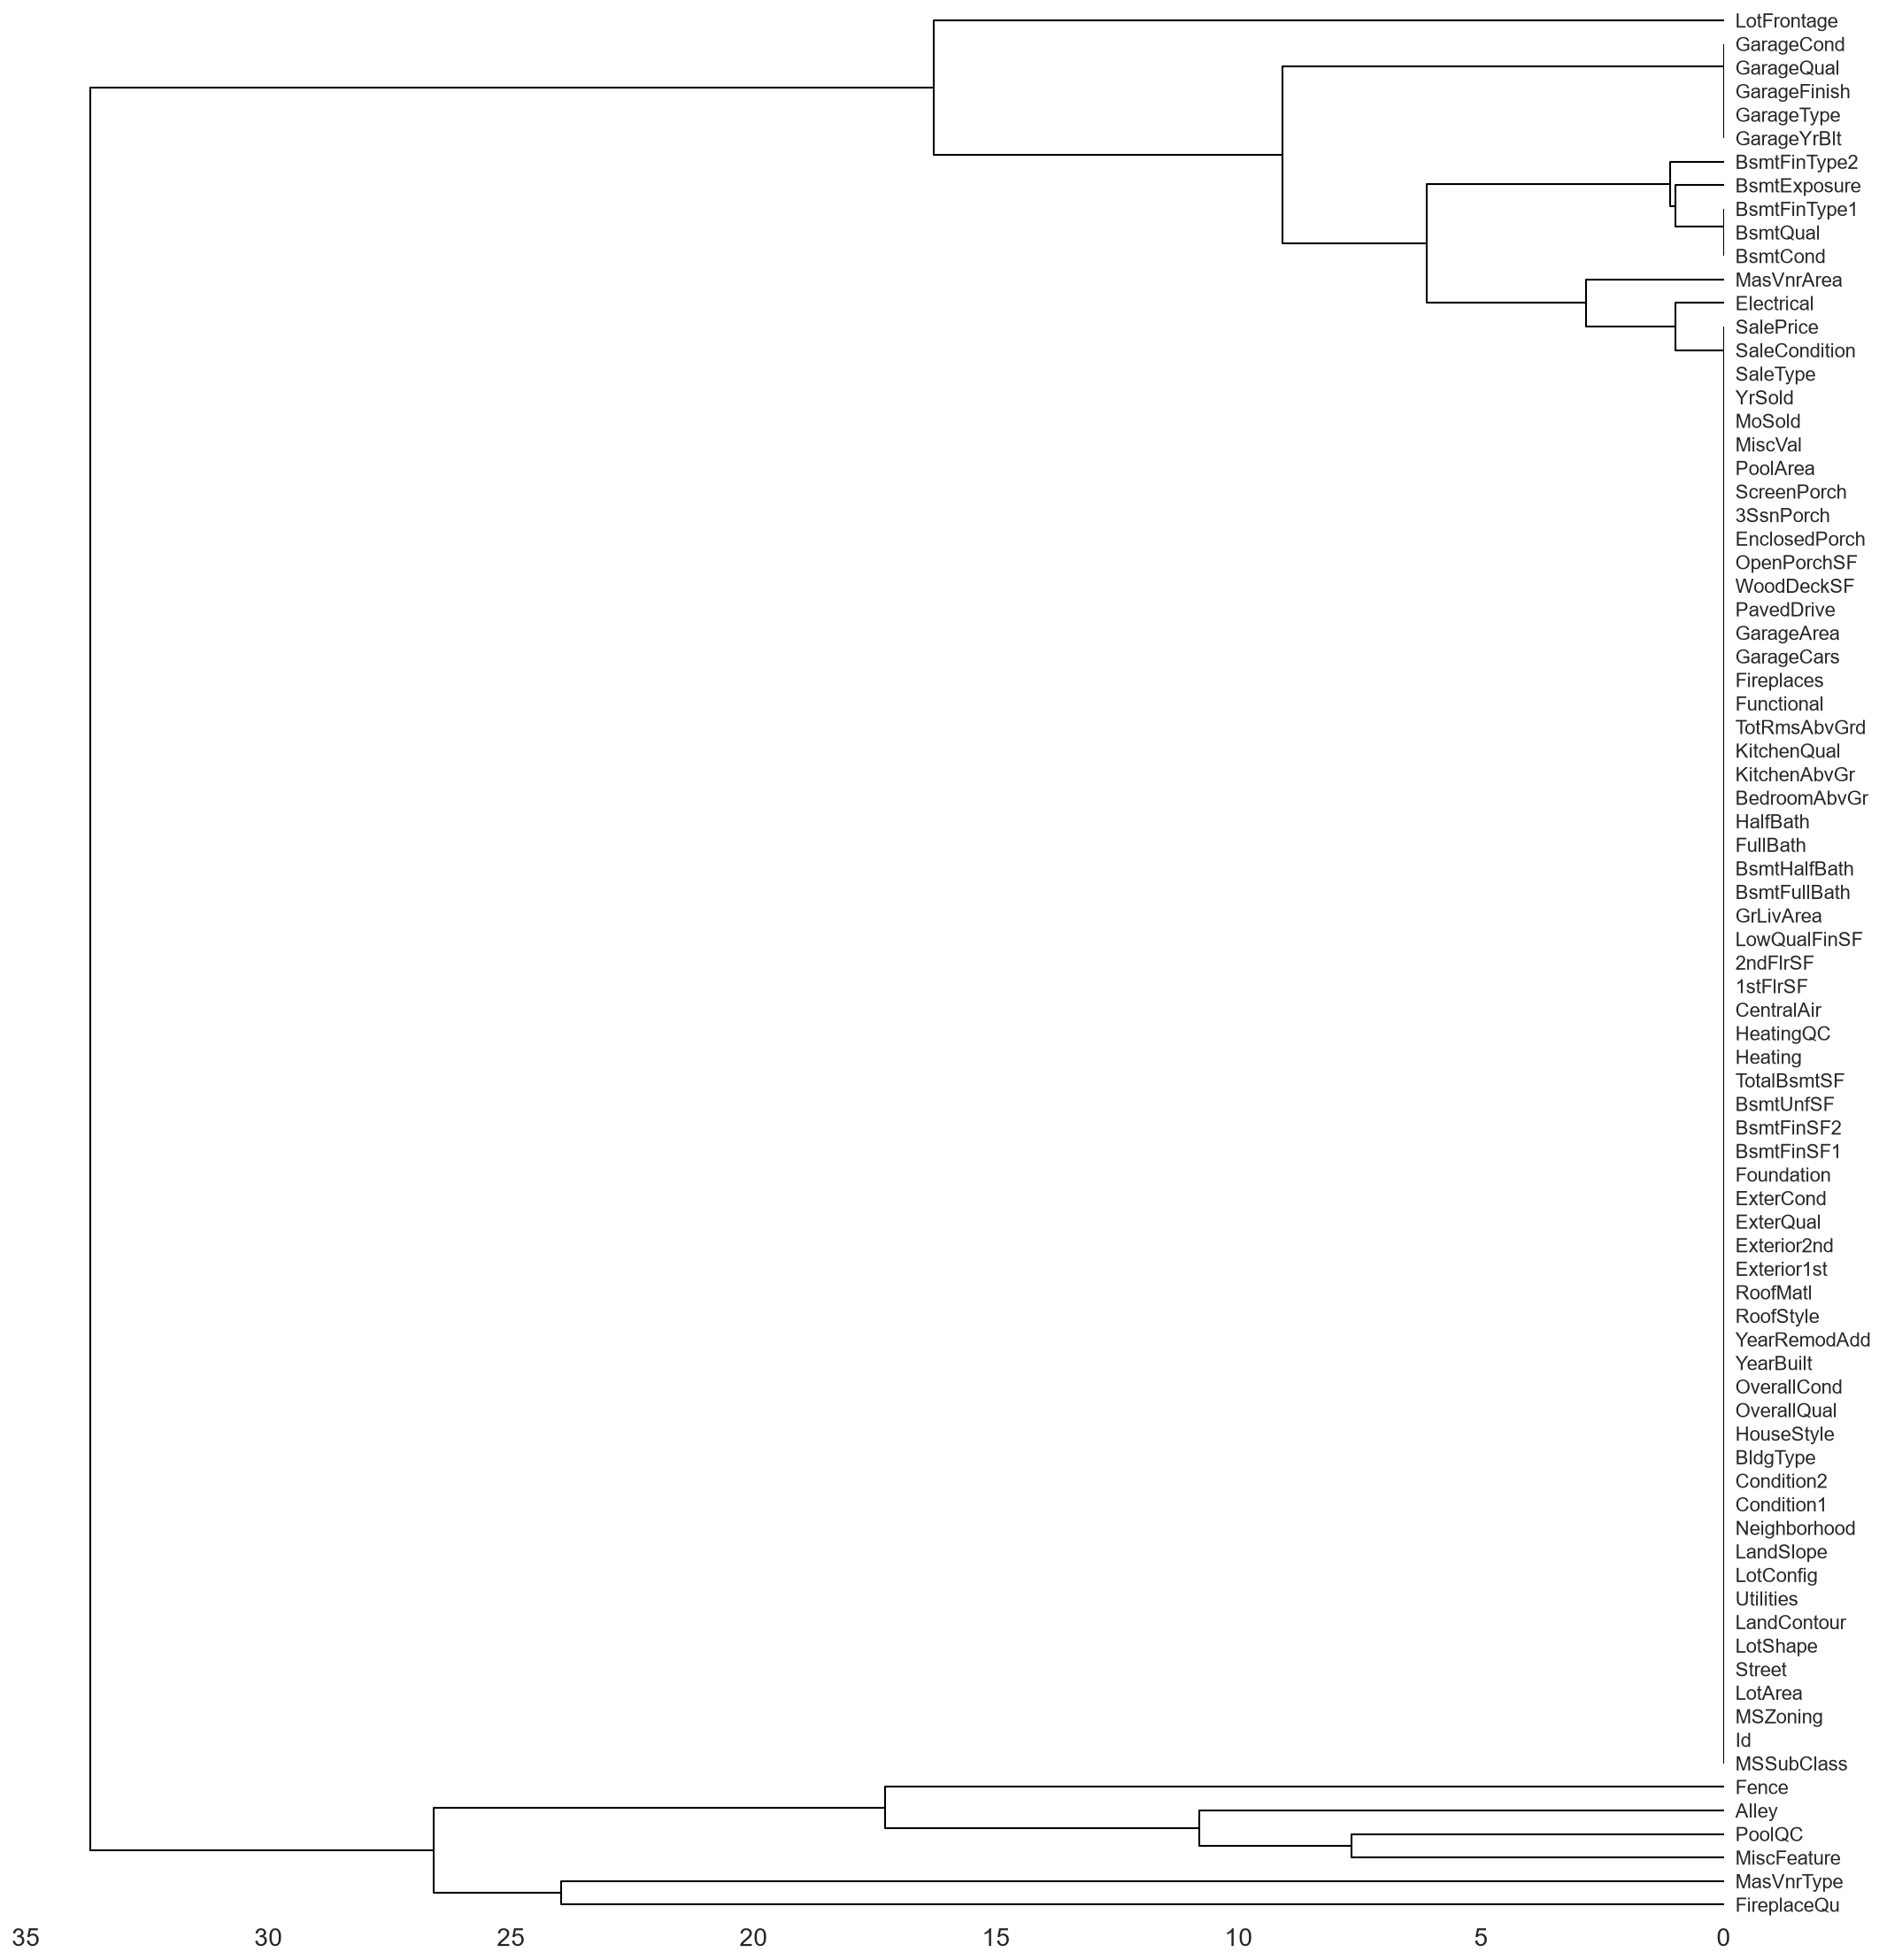

In [14]:
msno.dendrogram(train)
save_figures('house_cell_21')

The dendrogram uses hierarchical clustering from SciPy, which joins first the columns whose gaps match most closely. Columns joined at a distance of zero predict each other's gaps exactly: for example, one is always empty when the other is filled, or both are always filled. Here, these are the required columns, which are filled in every record. Columns joined close to zero match well but not perfectly, and the height of the join shows how often their gaps disagree. The plot labels up to 50 columns clearly and turns sideways for larger datasets.

**Problems in the data**
With the basic summaries done, the next step is the two main problems that EDA looks for: missing values and outliers (values far from the rest). Box plots later in Part A are used for the outliers.

**Skewness and kurtosis**

In [15]:
house_moments=pd.DataFrame({'n':numeric_features.count(),'Skewness':numeric_features.skew(),'Excess kurtosis':numeric_features.kurt()})
display(house_moments.round(4))
house_moments.to_csv(OUT/'house_numeric_moments.csv')

,n,Skewness,Excess kurtosis
Id,1460,0.0000,-1.2000
MSSubClass,1460,1.4077,1.5802
LotFrontage,1201,2.1636,17.4529
LotArea,1460,12.2077,203.2433
OverallQual,1460,0.2169,0.0963
OverallCond,1460,0.6931,1.1064
YearBuilt,1460,-0.6135,-0.4396
YearRemodAdd,1460,-0.5036,-1.2722
MasVnrArea,1452,2.6691,10.0824
BsmtFinSF1,1460,1.6855,11.1182


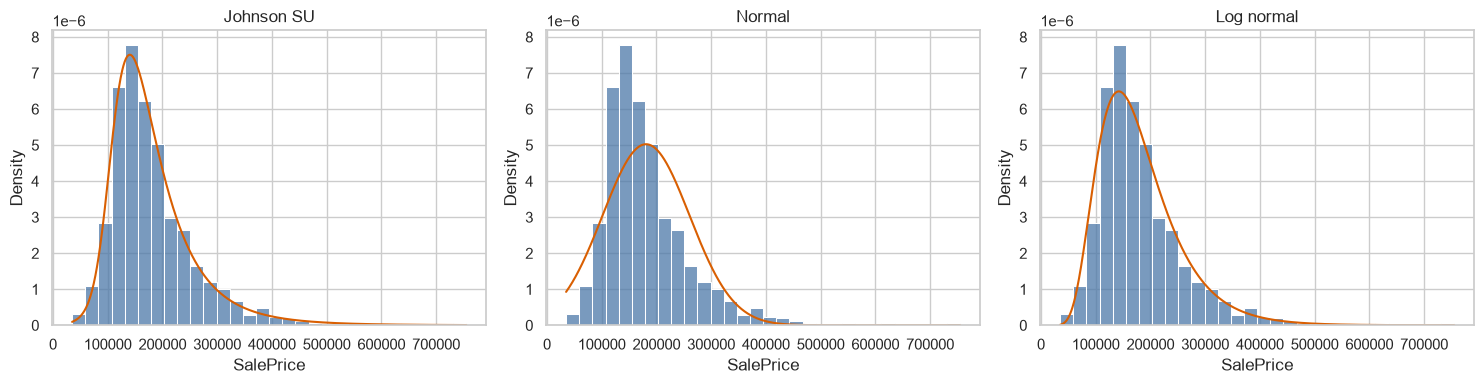

In [16]:
y=train['SalePrice']
fig,axes=plt.subplots(1,3,figsize=(15,4))
grid=np.linspace(y.min(),y.max(),1000)
for ax,(label,dist) in zip(axes,[('Johnson SU',st.johnsonsu),('Normal',st.norm),('Log normal',st.lognorm)]):
    sns.histplot(x=y,stat='density',bins=30,ax=ax,color='#4c78a8')
    params=dist.fit(y)
    ax.plot(grid,dist.pdf(grid,*params),color='#d95f02')
    ax.set(title=label,xlabel='SalePrice')
fig.tight_layout()
save_figures('house_cell_25')

SalePrice is not normally distributed, so it would need transforming before a regression. A log transform works well, but the closest fit among the distributions tried is the unbounded Johnson distribution.

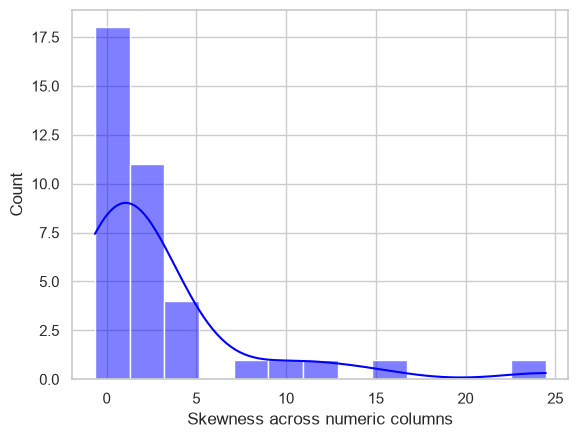

In [17]:
sns.histplot(x=numeric_features.skew(),kde=True,color='blue'); plt.xlabel('Skewness across numeric columns')
save_figures('house_cell_27')

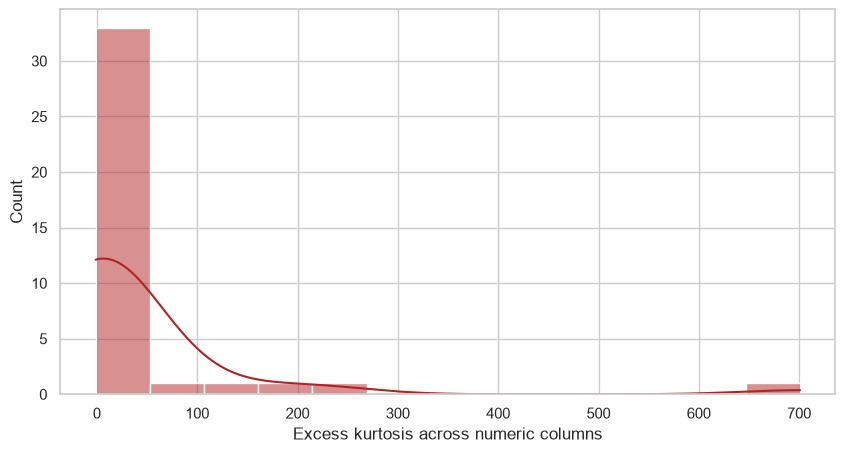

In [18]:
plt.figure(figsize=(10,5)); sns.histplot(x=numeric_features.kurt(),color='firebrick',kde=True); plt.xlabel('Excess kurtosis across numeric columns')
save_figures('house_cell_28')

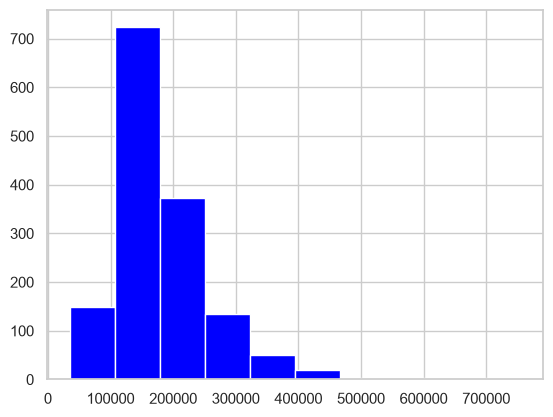

In [19]:
plt.hist(train['SalePrice'],orientation = 'vertical',histtype = 'bar', color ='blue')
None
save_figures('house_cell_29')

Raw SalePrice skew: 1.8828757597682118 log skew: 0.1213350622052098


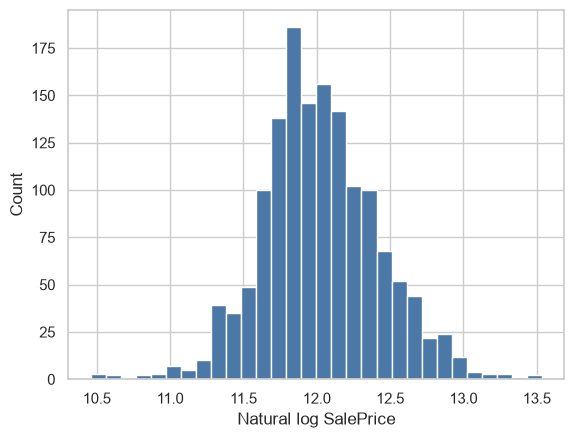

In [20]:
target=np.log(train['SalePrice'])
print('Raw SalePrice skew:',train.SalePrice.skew(),'log skew:',target.skew())
plt.hist(target,bins=30,color='#4c78a8'); plt.xlabel('Natural log SalePrice'); plt.ylabel('Count')
save_figures('house_cell_30')

Correlation between each numeric column and SalePrice.

In [21]:
correlation = numeric_features.corr()
print(correlation['SalePrice'].sort_values(ascending = False),'\n')
save_figures('house_cell_32')

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

To look further, I use four plots:
- correlation heatmap
- zoomed heatmap
- pair plot
- scatter plots

### Correlation Heat Map

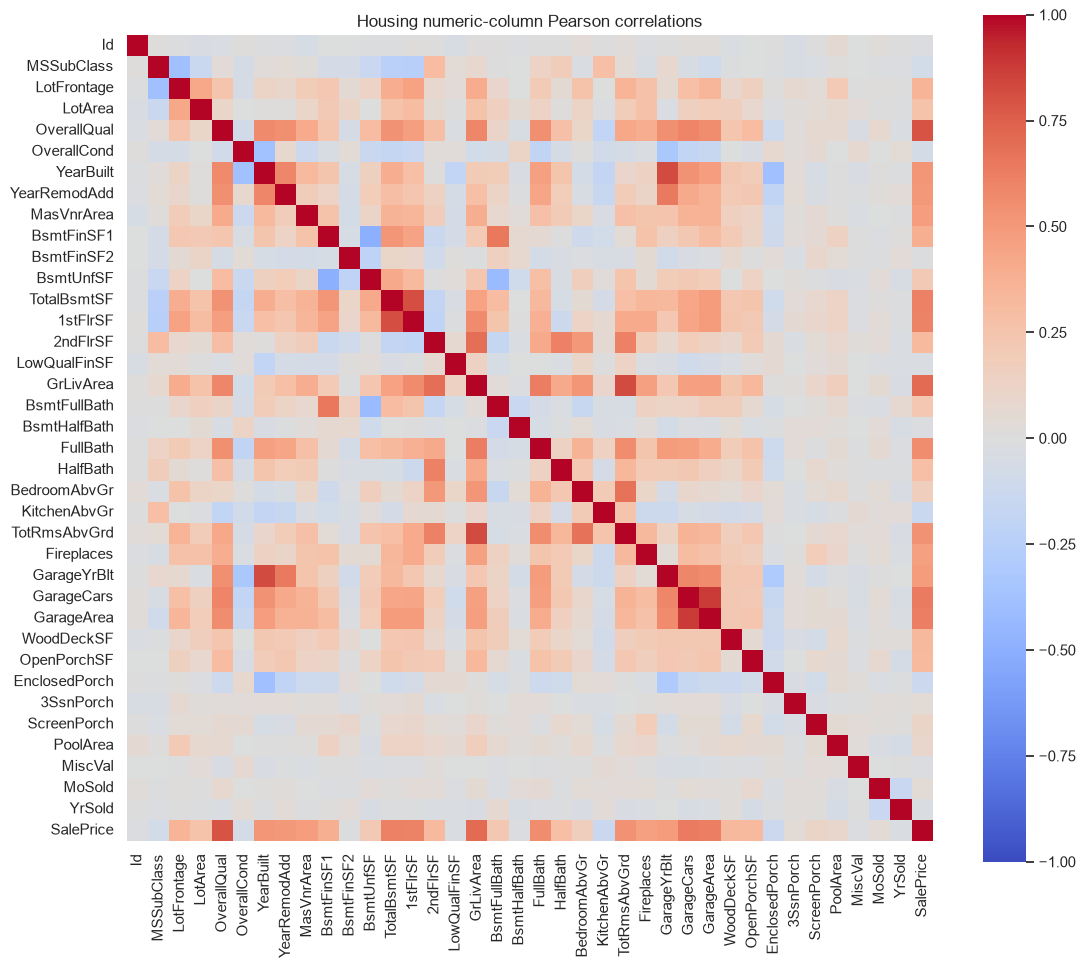

In [22]:
fig,ax=plt.subplots(figsize=(13,11)); sns.heatmap(correlation,vmin=-1,vmax=1,center=0,cmap='coolwarm',square=True,ax=ax); ax.set_title('Housing numeric-column Pearson correlations')
save_figures('house_cell_35')

The heatmap gives a quick overview of which columns are correlated. Two strongly correlated blocks stand out: 'TotalBsmtSF' with '1stFlrSF', and the 'Garage' columns. These correlations are strong enough to suggest multicollinearity, which means two inputs carry almost the same information. A heatmap is a useful first check for this when choosing features.

'GrLivArea', 'TotalBsmtSF' and 'OverallQual' are the columns most strongly correlated with SalePrice. Other columns are also correlated with it, so the zoomed heatmap looks more closely.

### Zoomed HeatMap

#### SalePrice Correlation matrix

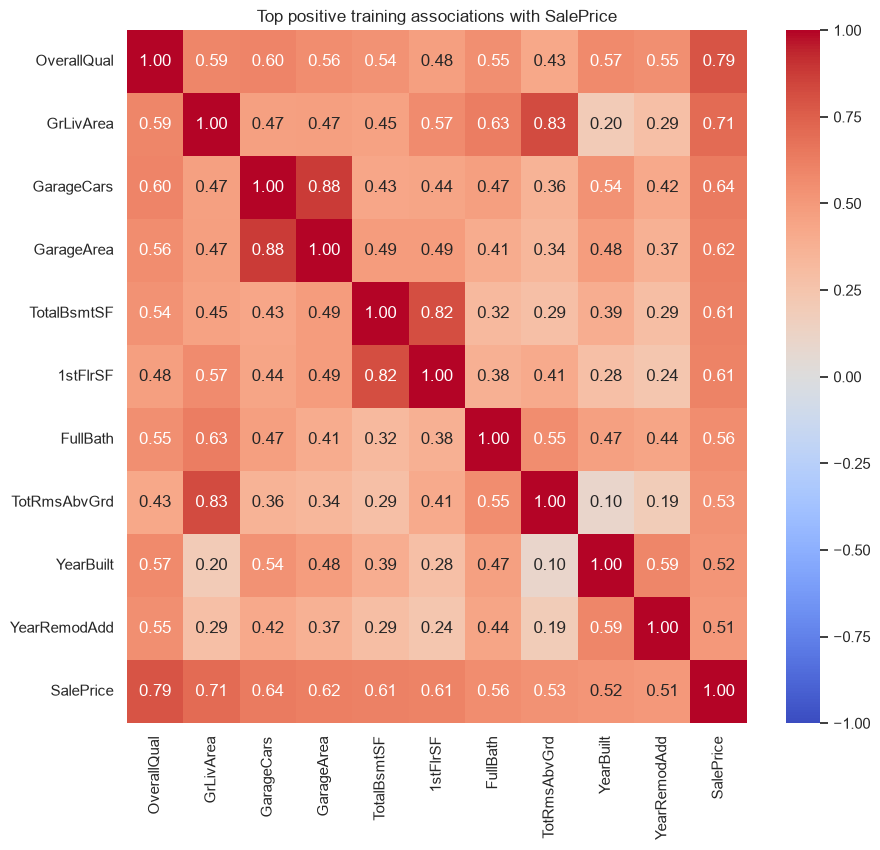

In [23]:
cols=correlation['SalePrice'].drop('SalePrice').nlargest(10).index.tolist()+['SalePrice']
cm=train[cols].corr()
fig,ax=plt.subplots(figsize=(10,9));sns.heatmap(cm,vmin=-1,vmax=1,center=0,annot=True,fmt='.2f',cmap='coolwarm',ax=ax);ax.set_title('Top positive training associations with SalePrice')
save_figures('house_cell_39')

The zoomed heatmap confirms that GarageCars and GarageArea are closely correlated, as are TotalBsmtSF and 1stFlrSF.

Observations:
- 'OverallQual', 'GrLivArea' and 'TotalBsmtSF' are strongly correlated with 'SalePrice'.
- 'GarageCars' and 'GarageArea' are strongly correlated, because the number of cars a garage holds depends on its area. Only one is needed. 'GarageCars' is the better choice, as its correlation with 'SalePrice' is higher.
- 'TotalBsmtSF' and '1stFlrSF' also carry almost the same information, so 'TotalBsmtSF' is enough.
- 'TotRmsAbvGrd' and 'GrLivArea' are a similar pair.
- 'YearBuilt' is only slightly correlated with 'SalePrice'. A firm conclusion would need further analysis, for example of prices over time.

### Pair Plot 

#### Pair Plot between 'SalePrice' and correlated variables 

A pair plot of 'OverallQual', 'TotalBsmtSF', 'GrLivArea', 'GarageArea', 'FullBath', 'YearBuilt' and 'YearRemodAdd' against SalePrice.

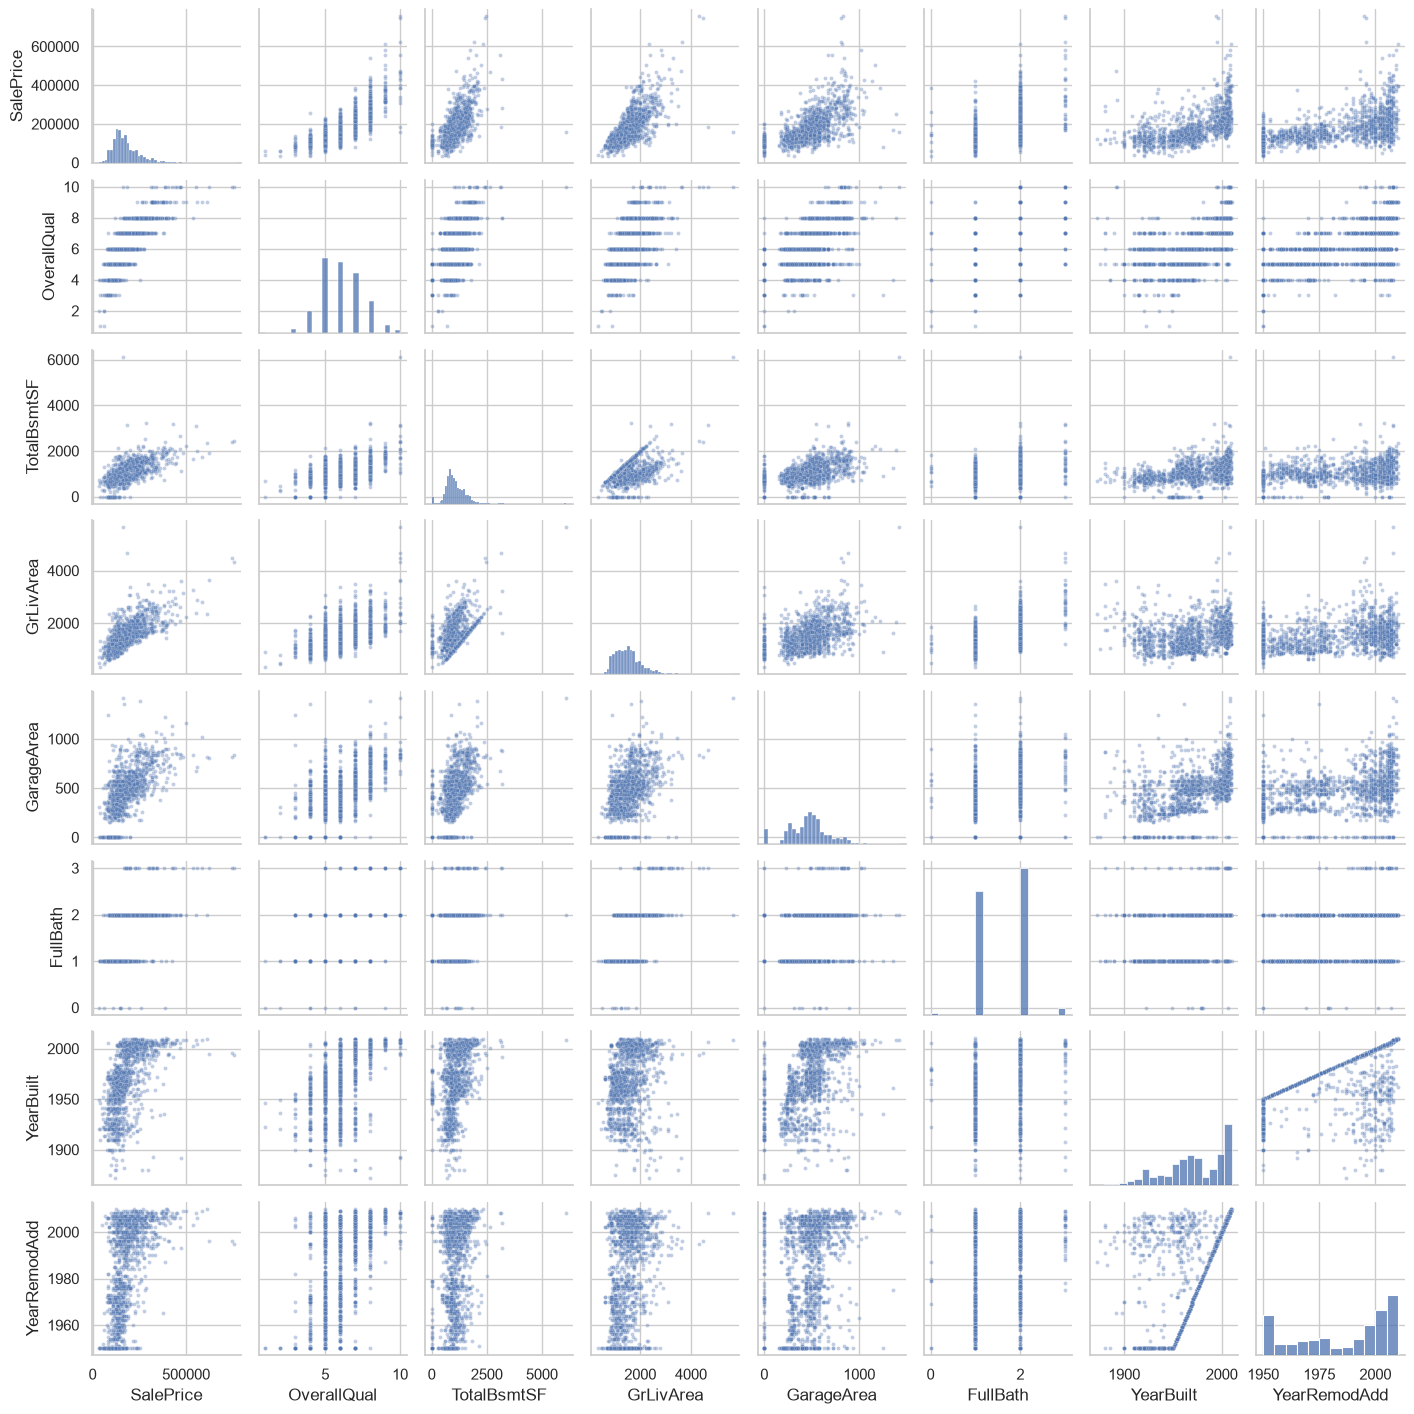

In [24]:
columns=['SalePrice','OverallQual','TotalBsmtSF','GrLivArea','GarageArea','FullBath','YearBuilt','YearRemodAdd']
sns.pairplot(train[columns],height=1.8,kind='scatter',diag_kind='hist',plot_kws={'s':8,'alpha':.35})
save_figures('house_cell_45')

The pair plot gives an overview of the correlated columns.
- 'TotalBsmtSF' against 'GrLivArea': the points sit below a straight edge. This is expected, because a basement is rarely larger than the living area above it.
- 'SalePrice' against 'YearBuilt': the lower edge of the points curves upwards, almost exponentially, and the upper edge shows the same trend. Prices of newer houses have risen faster.

### Scatter Plot 

#### Scatter plots between the most correlated variables

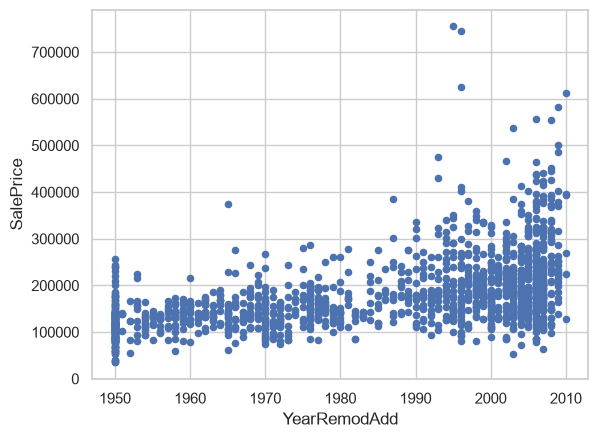

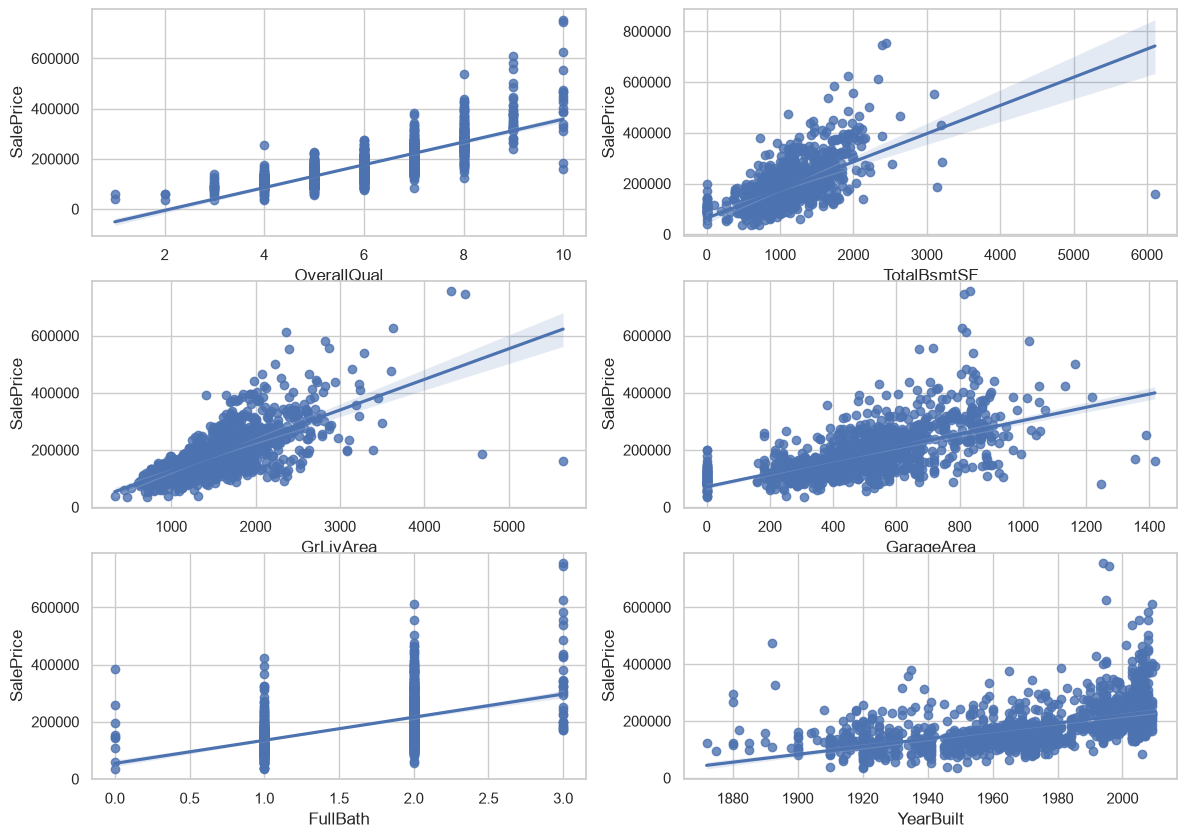

<Figure size 640x480 with 0 Axes>

In [25]:
fig, ((ax1, ax2), (ax3, ax4),(ax5,ax6)) = plt.subplots(nrows=3, ncols=2, figsize=(14,10))
OverallQual_scatter_plot = pd.concat([train['SalePrice'],train['OverallQual']],axis = 1)
sns.regplot(x='OverallQual',y = 'SalePrice',data = OverallQual_scatter_plot,scatter= True, fit_reg=True, ax=ax1)
TotalBsmtSF_scatter_plot = pd.concat([train['SalePrice'],train['TotalBsmtSF']],axis = 1)
sns.regplot(x='TotalBsmtSF',y = 'SalePrice',data = TotalBsmtSF_scatter_plot,scatter= True, fit_reg=True, ax=ax2)
GrLivArea_scatter_plot = pd.concat([train['SalePrice'],train['GrLivArea']],axis = 1)
sns.regplot(x='GrLivArea',y = 'SalePrice',data = GrLivArea_scatter_plot,scatter= True, fit_reg=True, ax=ax3)
GarageArea_scatter_plot = pd.concat([train['SalePrice'],train['GarageArea']],axis = 1)
sns.regplot(x='GarageArea',y = 'SalePrice',data = GarageArea_scatter_plot,scatter= True, fit_reg=True, ax=ax4)
FullBath_scatter_plot = pd.concat([train['SalePrice'],train['FullBath']],axis = 1)
sns.regplot(x='FullBath',y = 'SalePrice',data = FullBath_scatter_plot,scatter= True, fit_reg=True, ax=ax5)
YearBuilt_scatter_plot = pd.concat([train['SalePrice'],train['YearBuilt']],axis = 1)
sns.regplot(x='YearBuilt',y = 'SalePrice',data = YearBuilt_scatter_plot,scatter= True, fit_reg=True, ax=ax6)
YearRemodAdd_scatter_plot = pd.concat([train['SalePrice'],train['YearRemodAdd']],axis = 1)
YearRemodAdd_scatter_plot.plot.scatter('YearRemodAdd','SalePrice')
save_figures('house_cell_49')

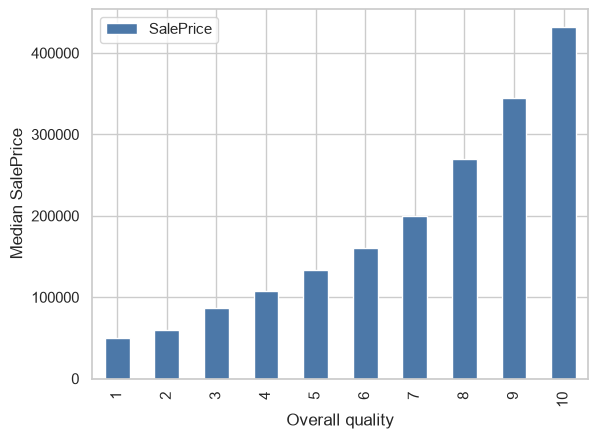

In [26]:
saleprice_overall_quality=train.pivot_table(index='OverallQual',values='SalePrice',aggfunc='median')
saleprice_overall_quality.plot(kind='bar',color='#4c78a8');plt.xlabel('Overall quality');plt.ylabel('Median SalePrice')
save_figures('house_cell_50')

#### Box plot - OverallQual

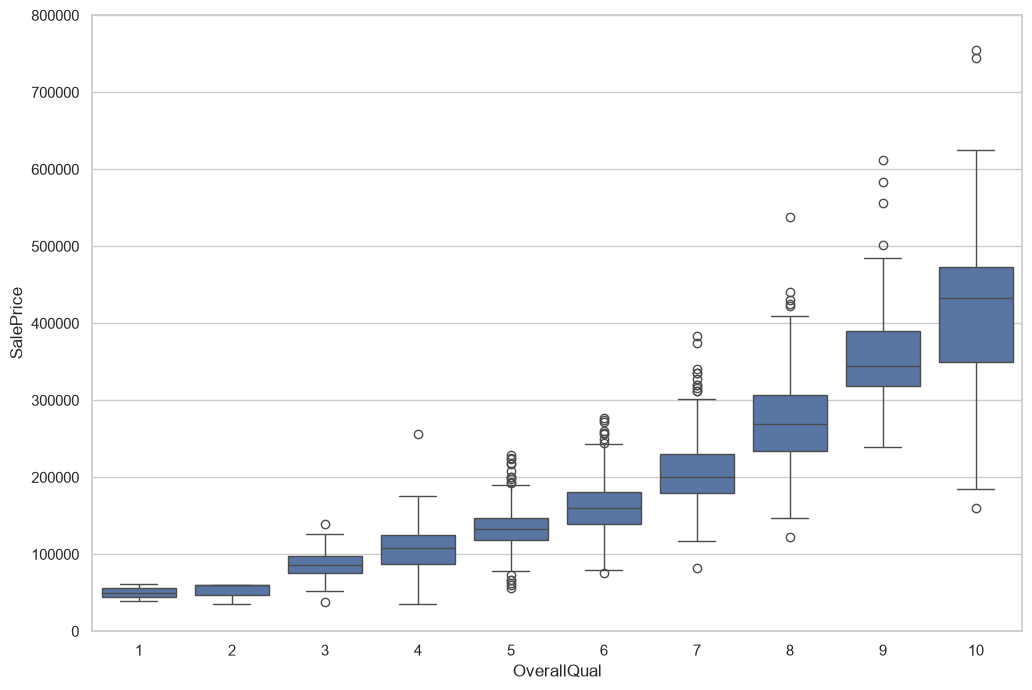

In [27]:
var = 'OverallQual'
data = pd.concat([train['SalePrice'], train[var]], axis=1)
f, ax = plt.subplots(figsize=(12, 8))
fig = sns.boxplot(x=var, y="SalePrice", data=data)
fig.axis(ymin=0, ymax=800000);
save_figures('house_cell_52')

#### Box plot - Neighborhood

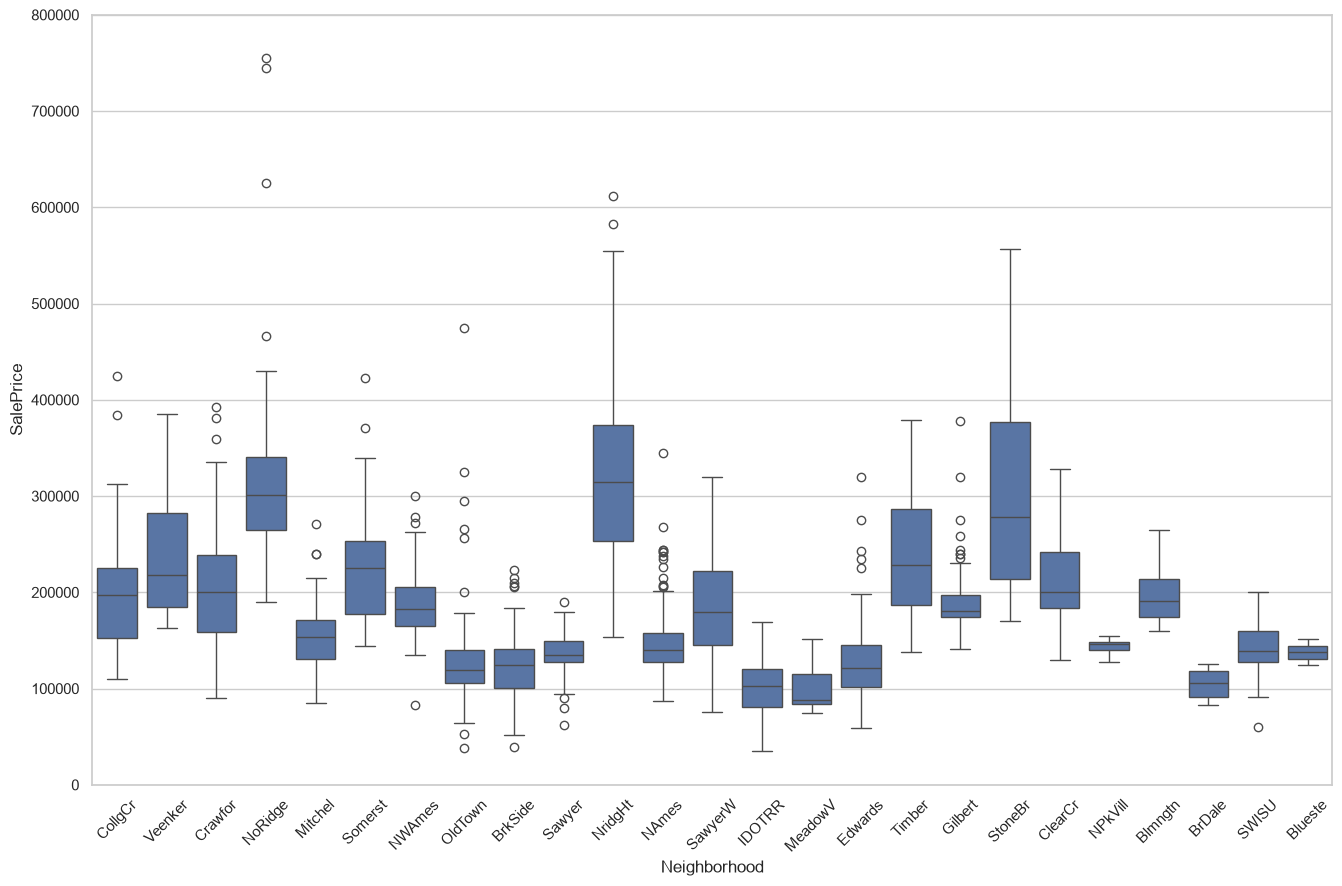

In [28]:
var = 'Neighborhood'
data = pd.concat([train['SalePrice'], train[var]], axis=1)
f, ax = plt.subplots(figsize=(16, 10))
fig = sns.boxplot(x=var, y="SalePrice", data=data)
fig.axis(ymin=0, ymax=800000);
xt = plt.xticks(rotation=45)
save_figures('house_cell_54')

#### Count Plot - Neighborhood

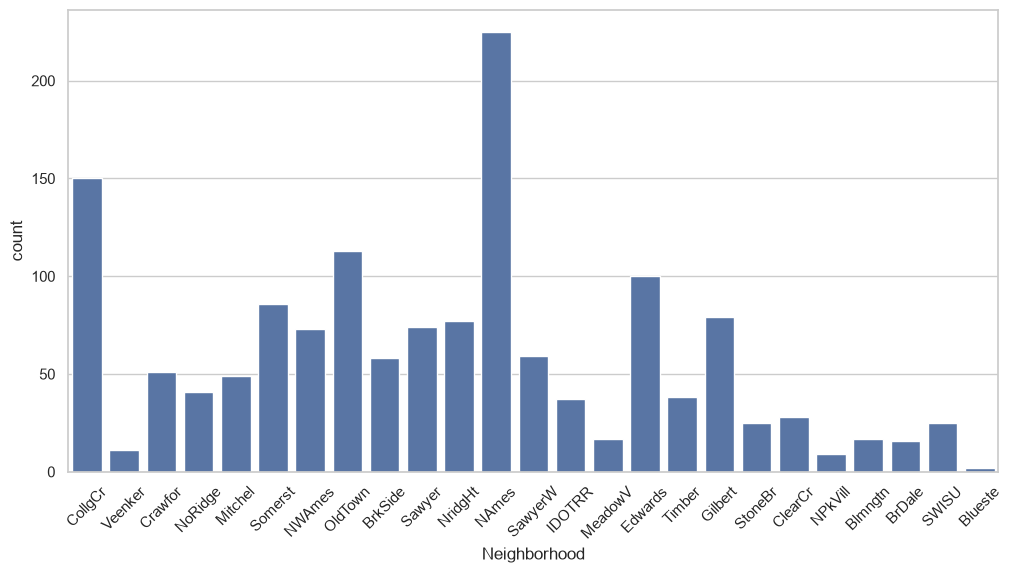

In [29]:
plt.figure(figsize = (12, 6))
sns.countplot(x = 'Neighborhood', data = data)
xt = plt.xticks(rotation=45)
save_figures('house_cell_56')

Neighbourhoods with similar prices could be grouped together to reduce the number of categories, a step that belongs to preprocessing.

For category columns, box plots show how SalePrice is spread within each category.

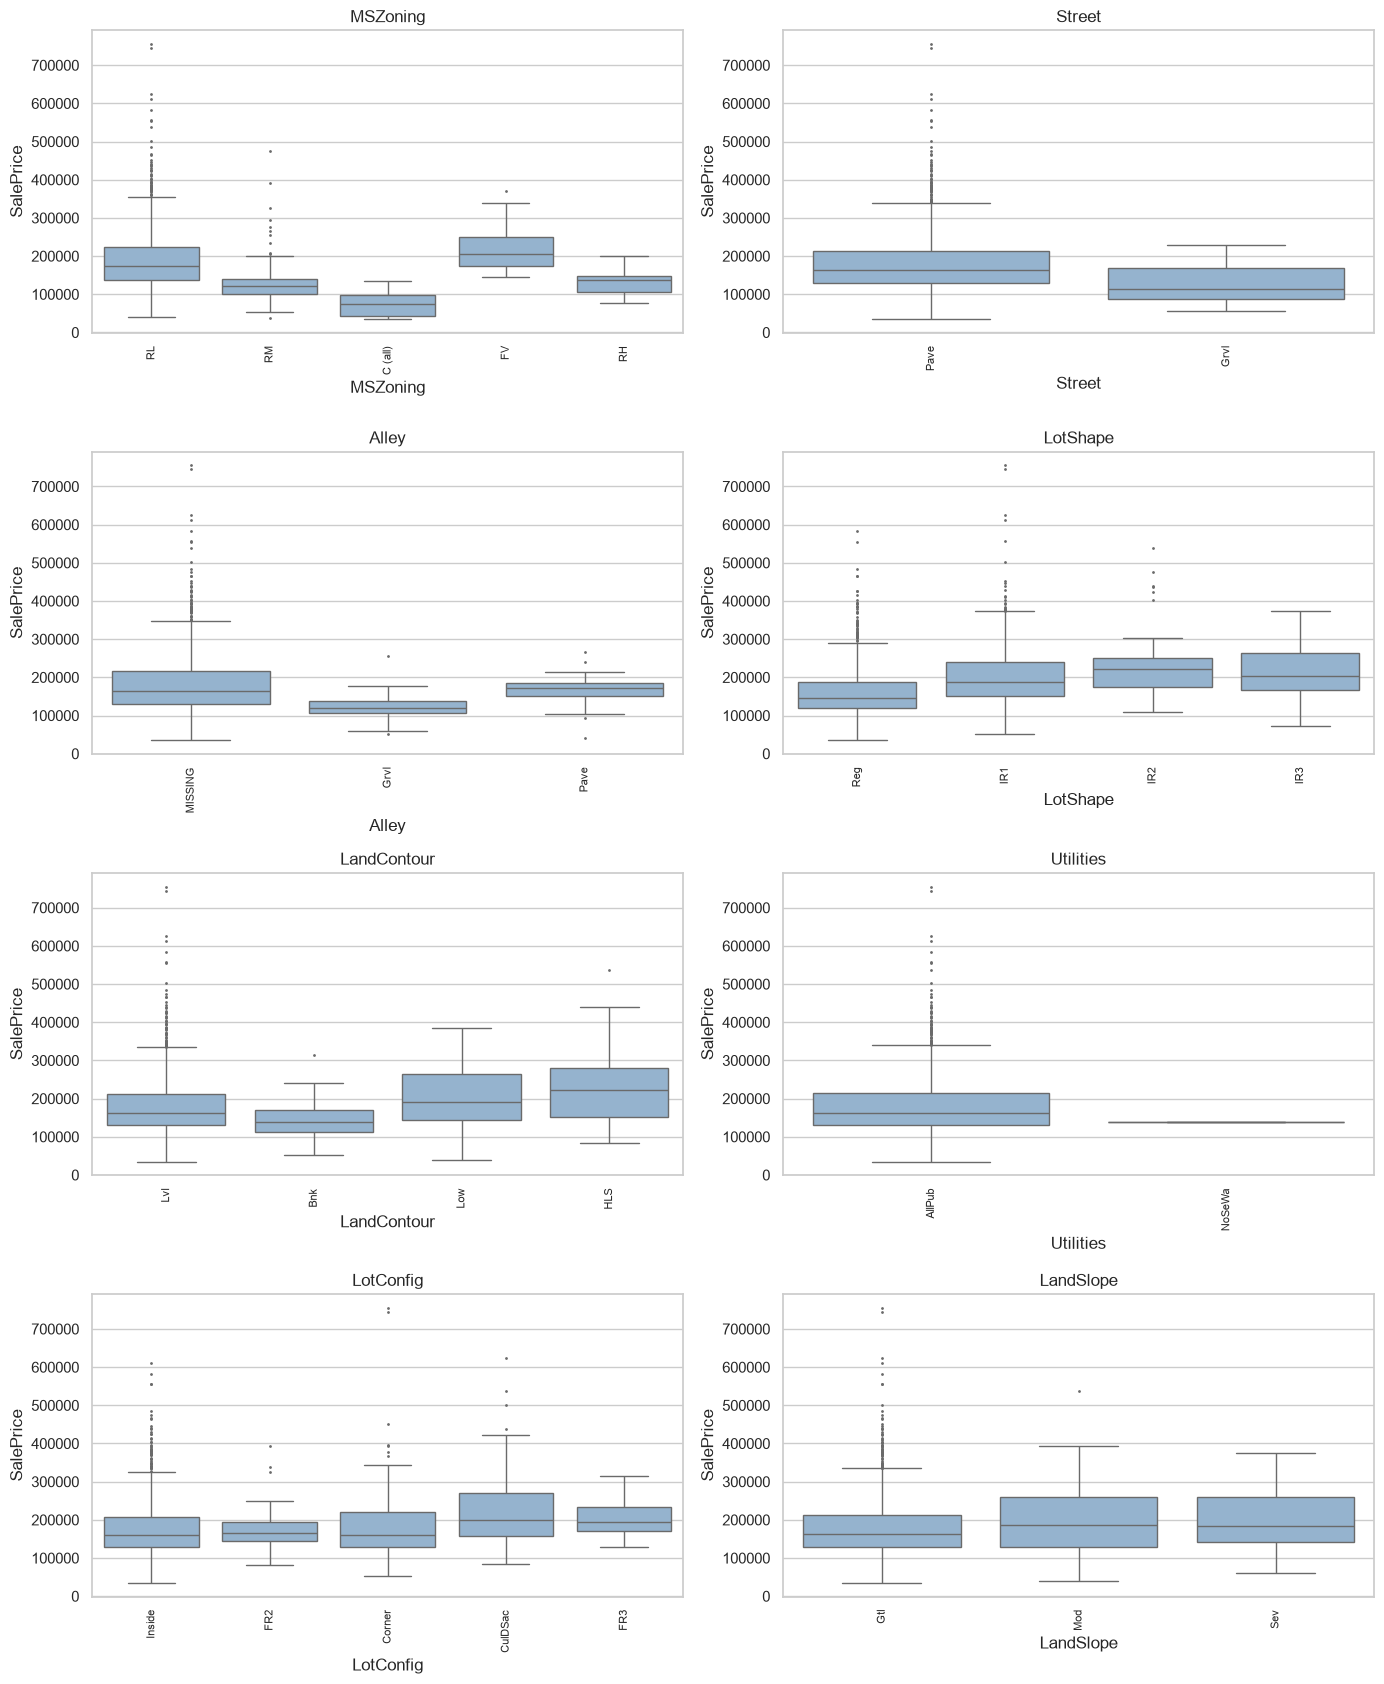

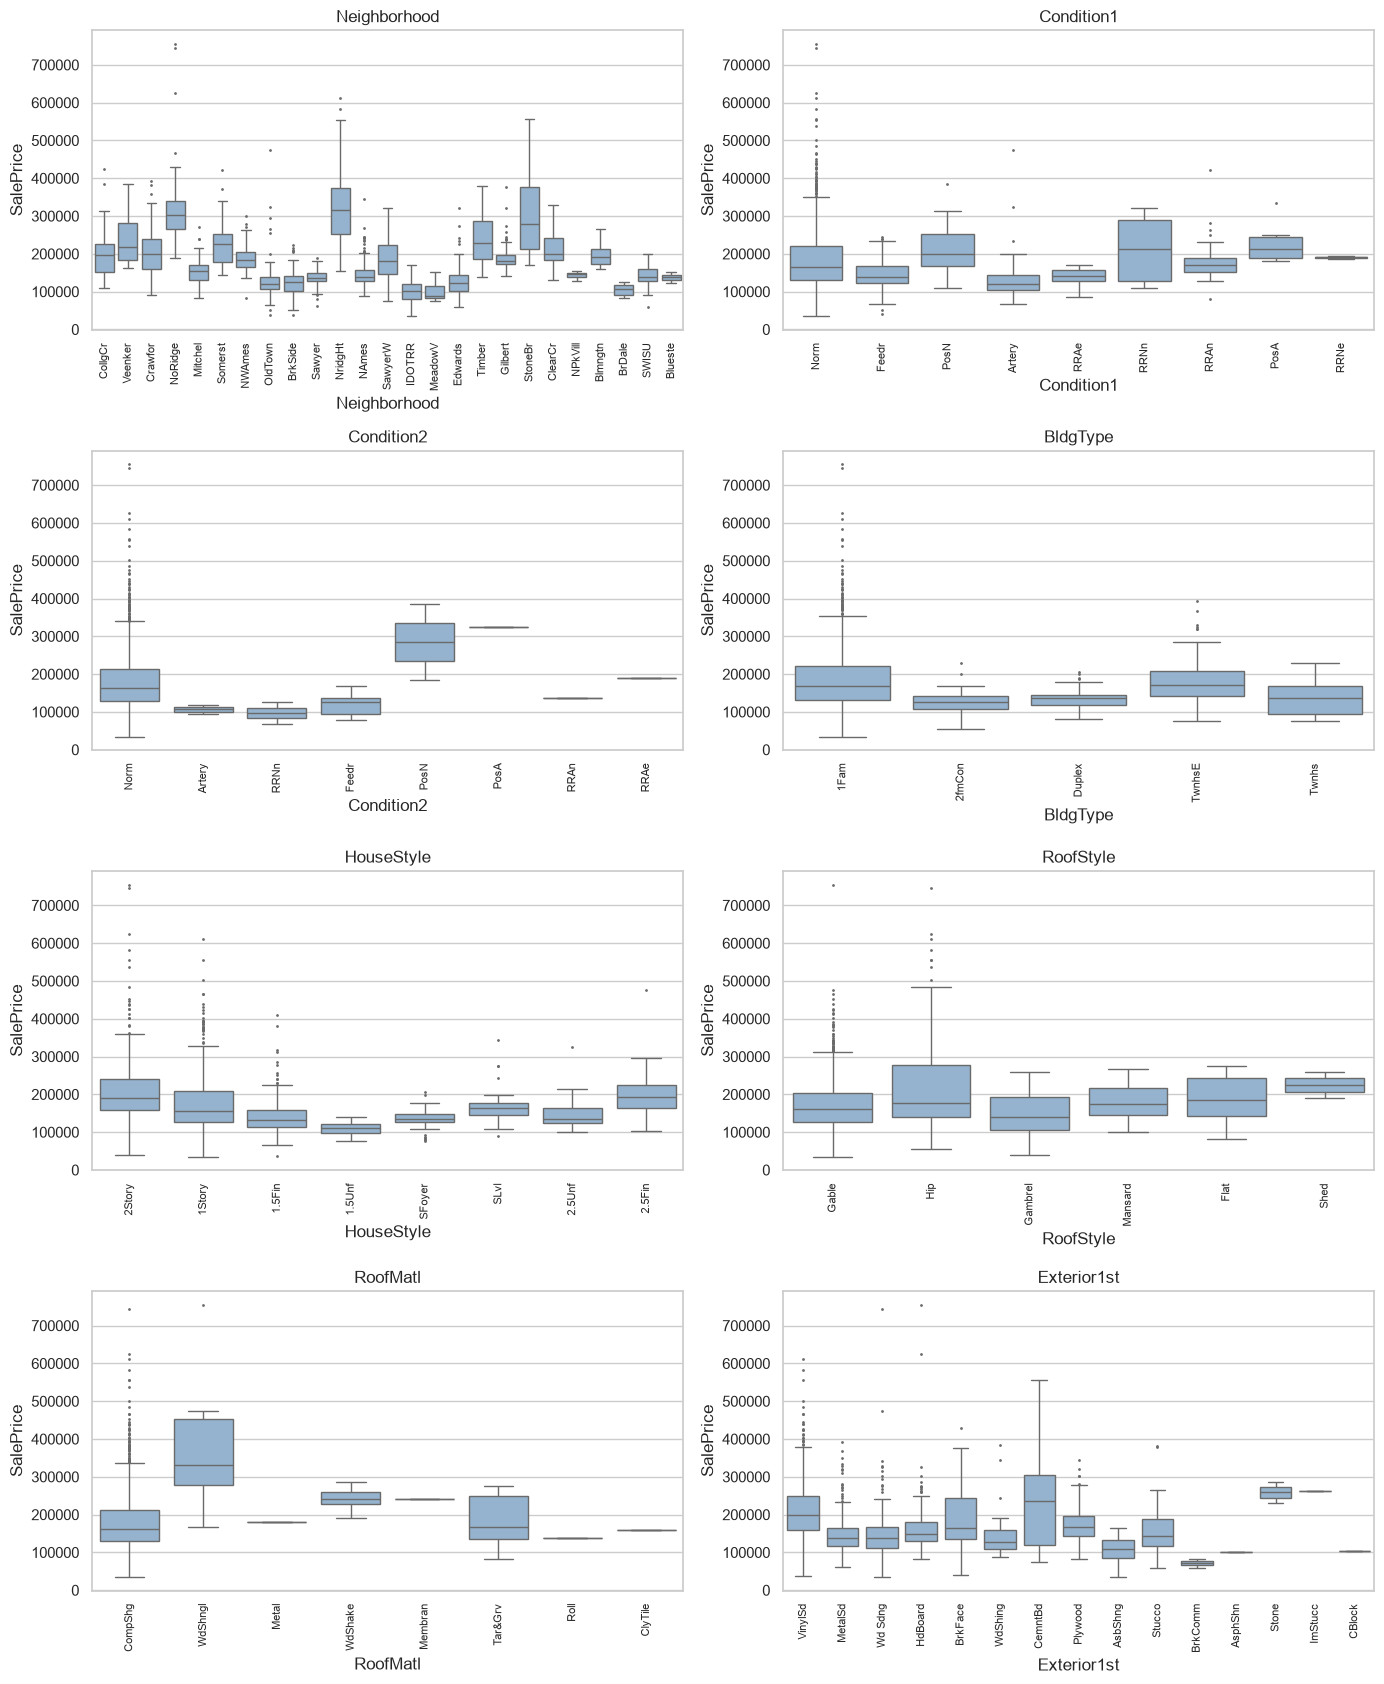

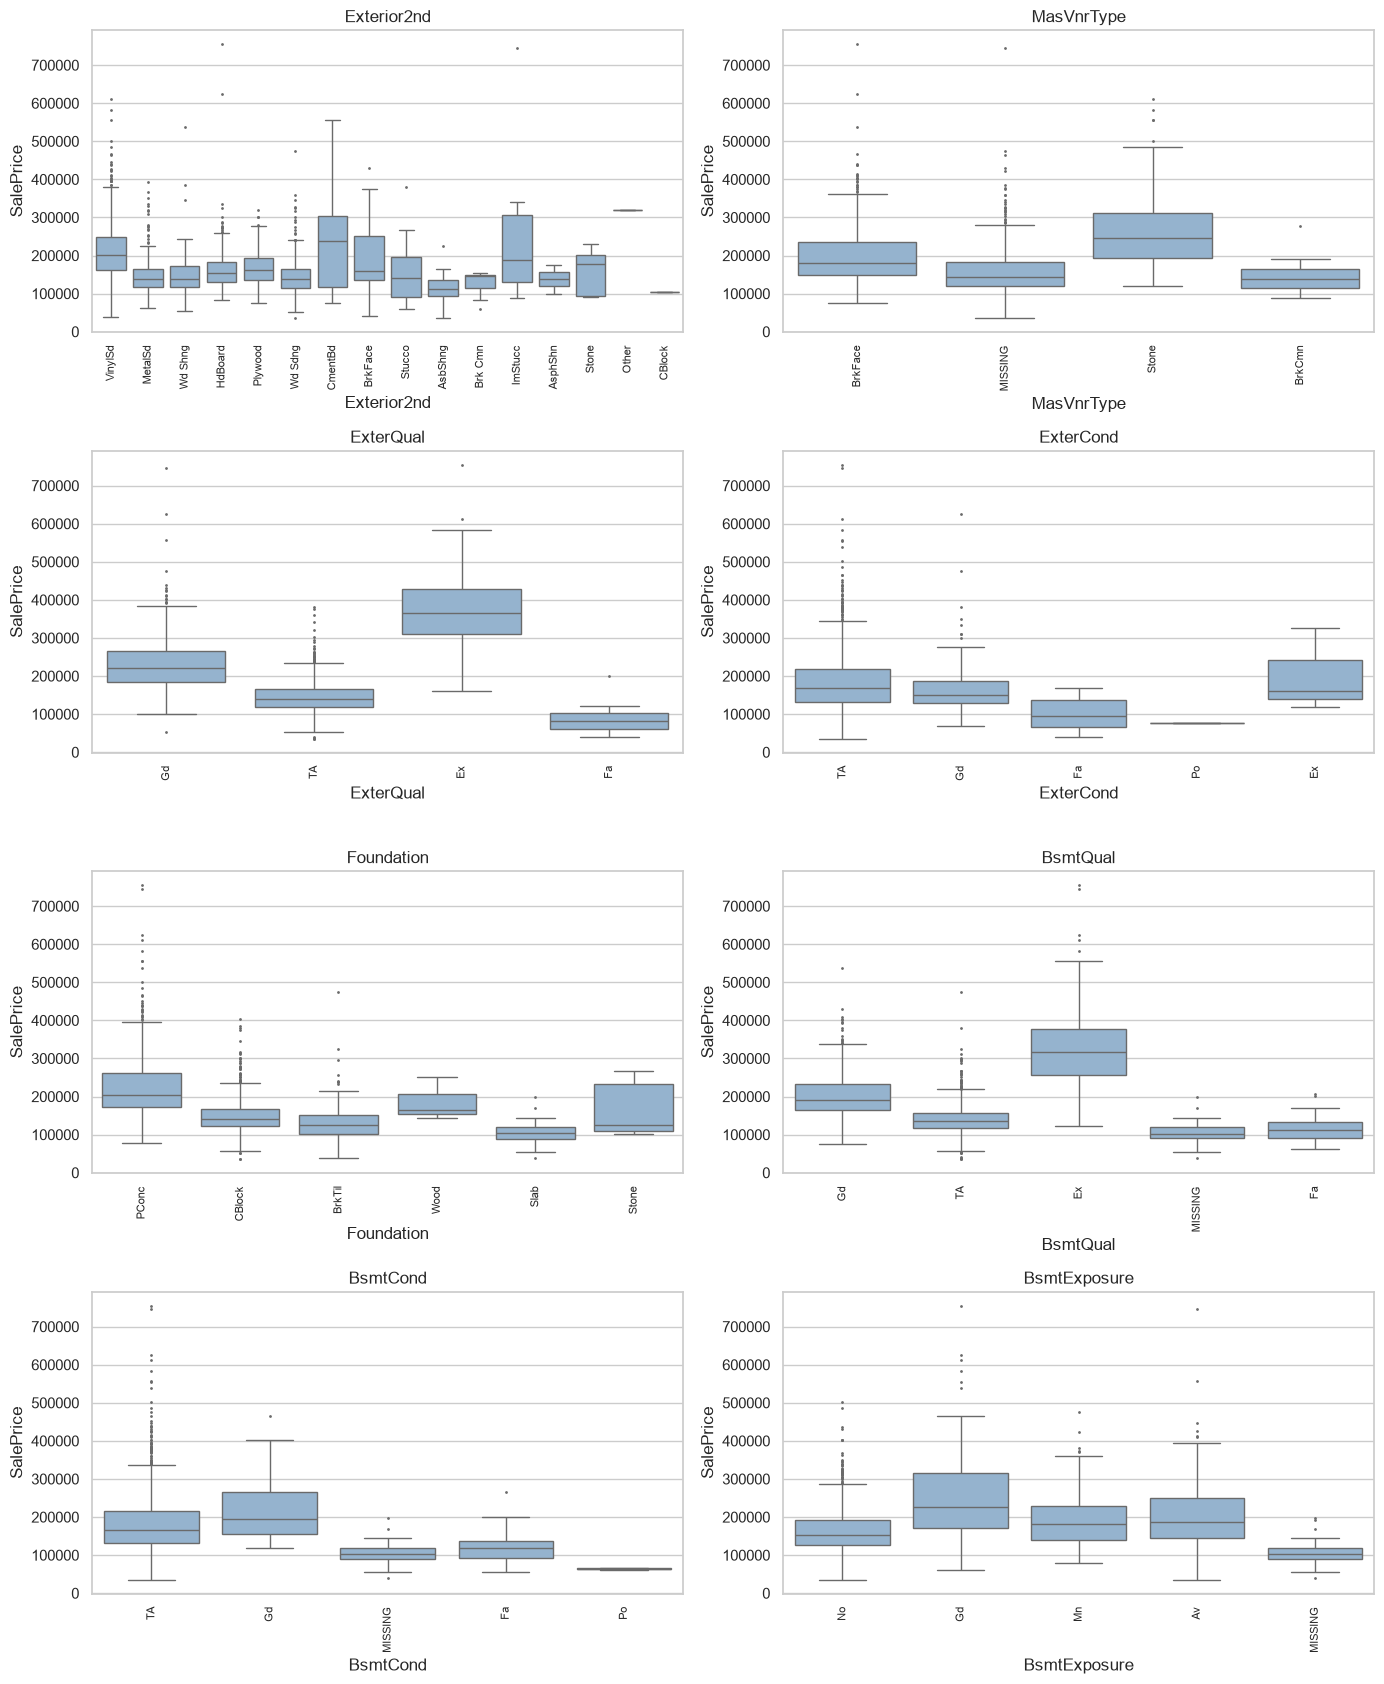

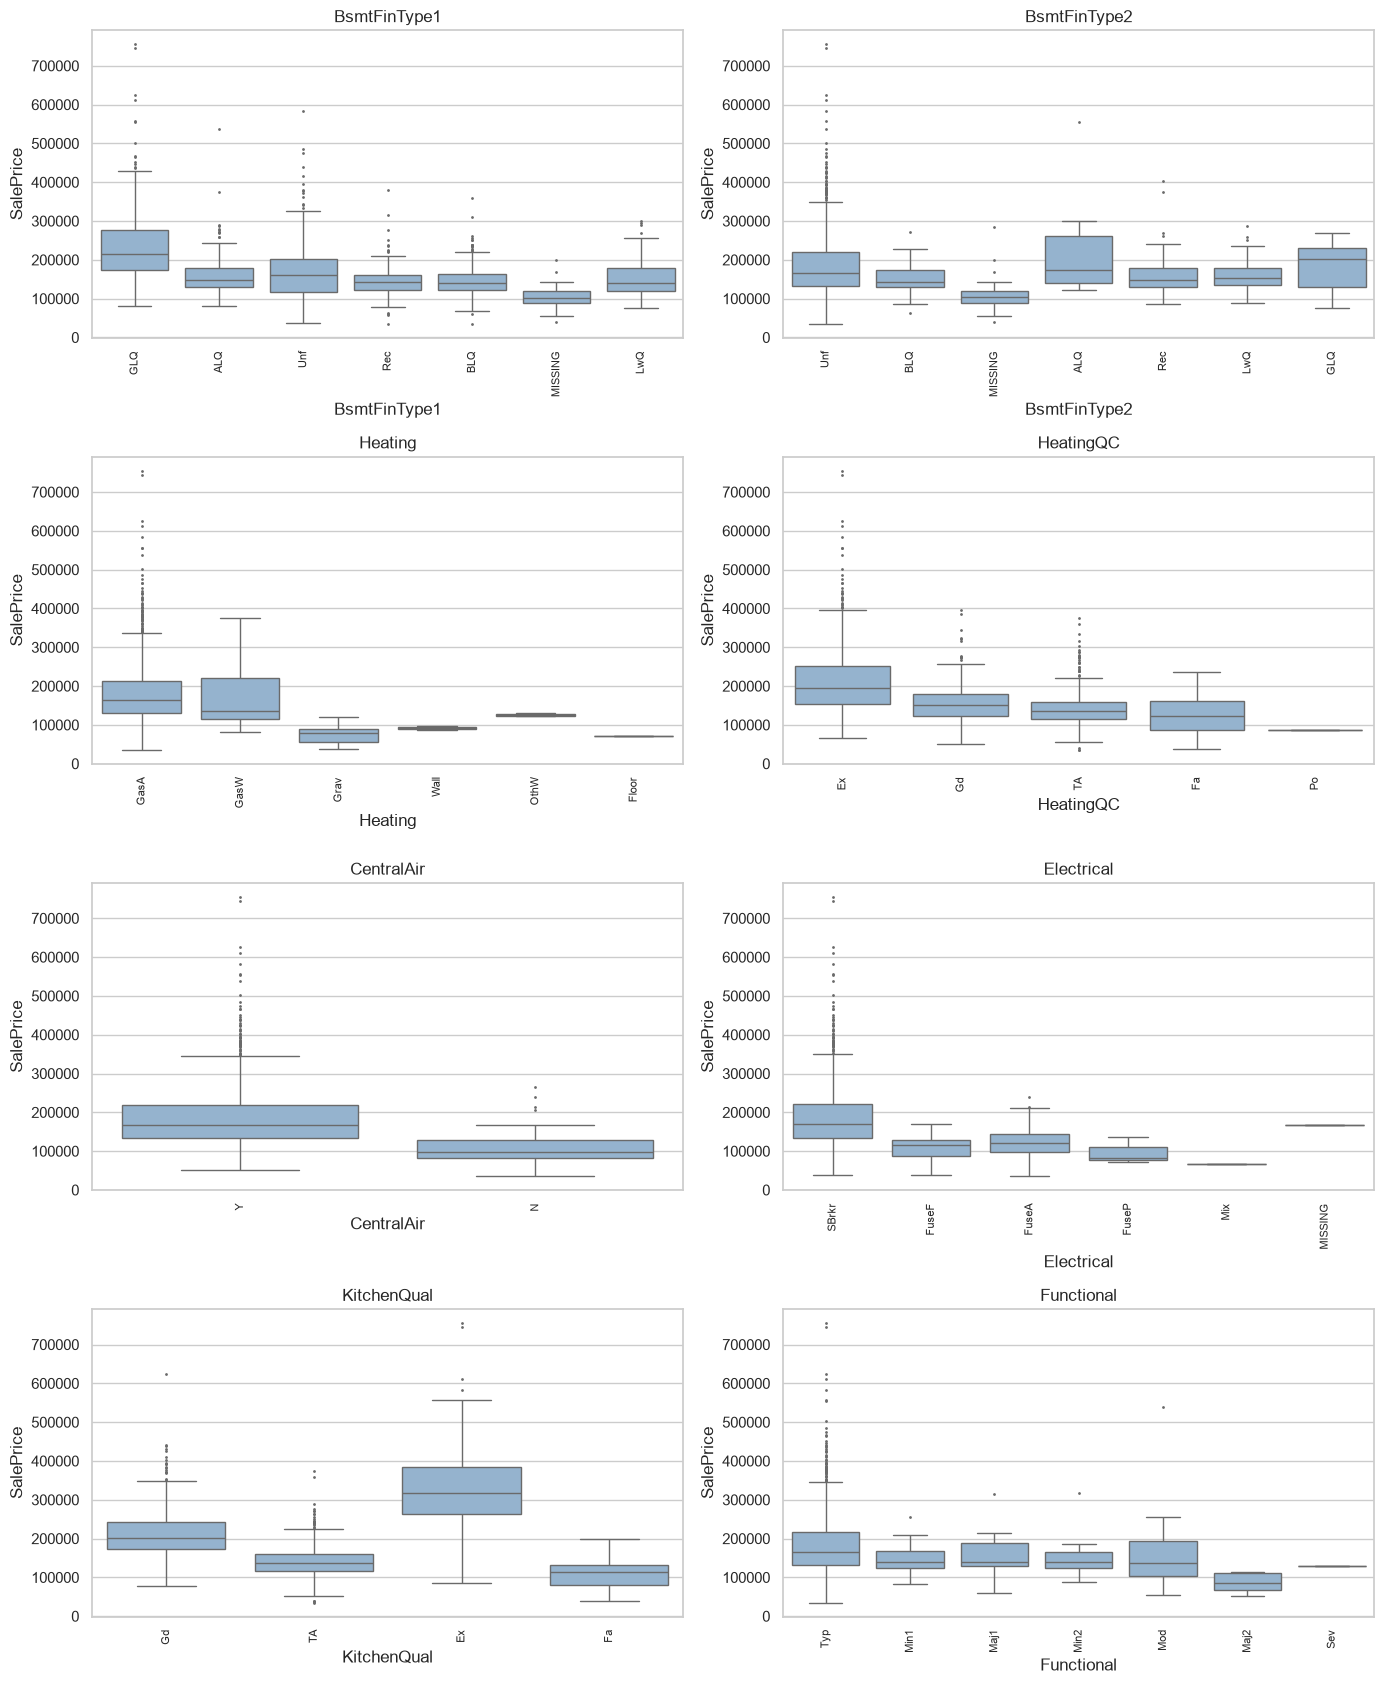

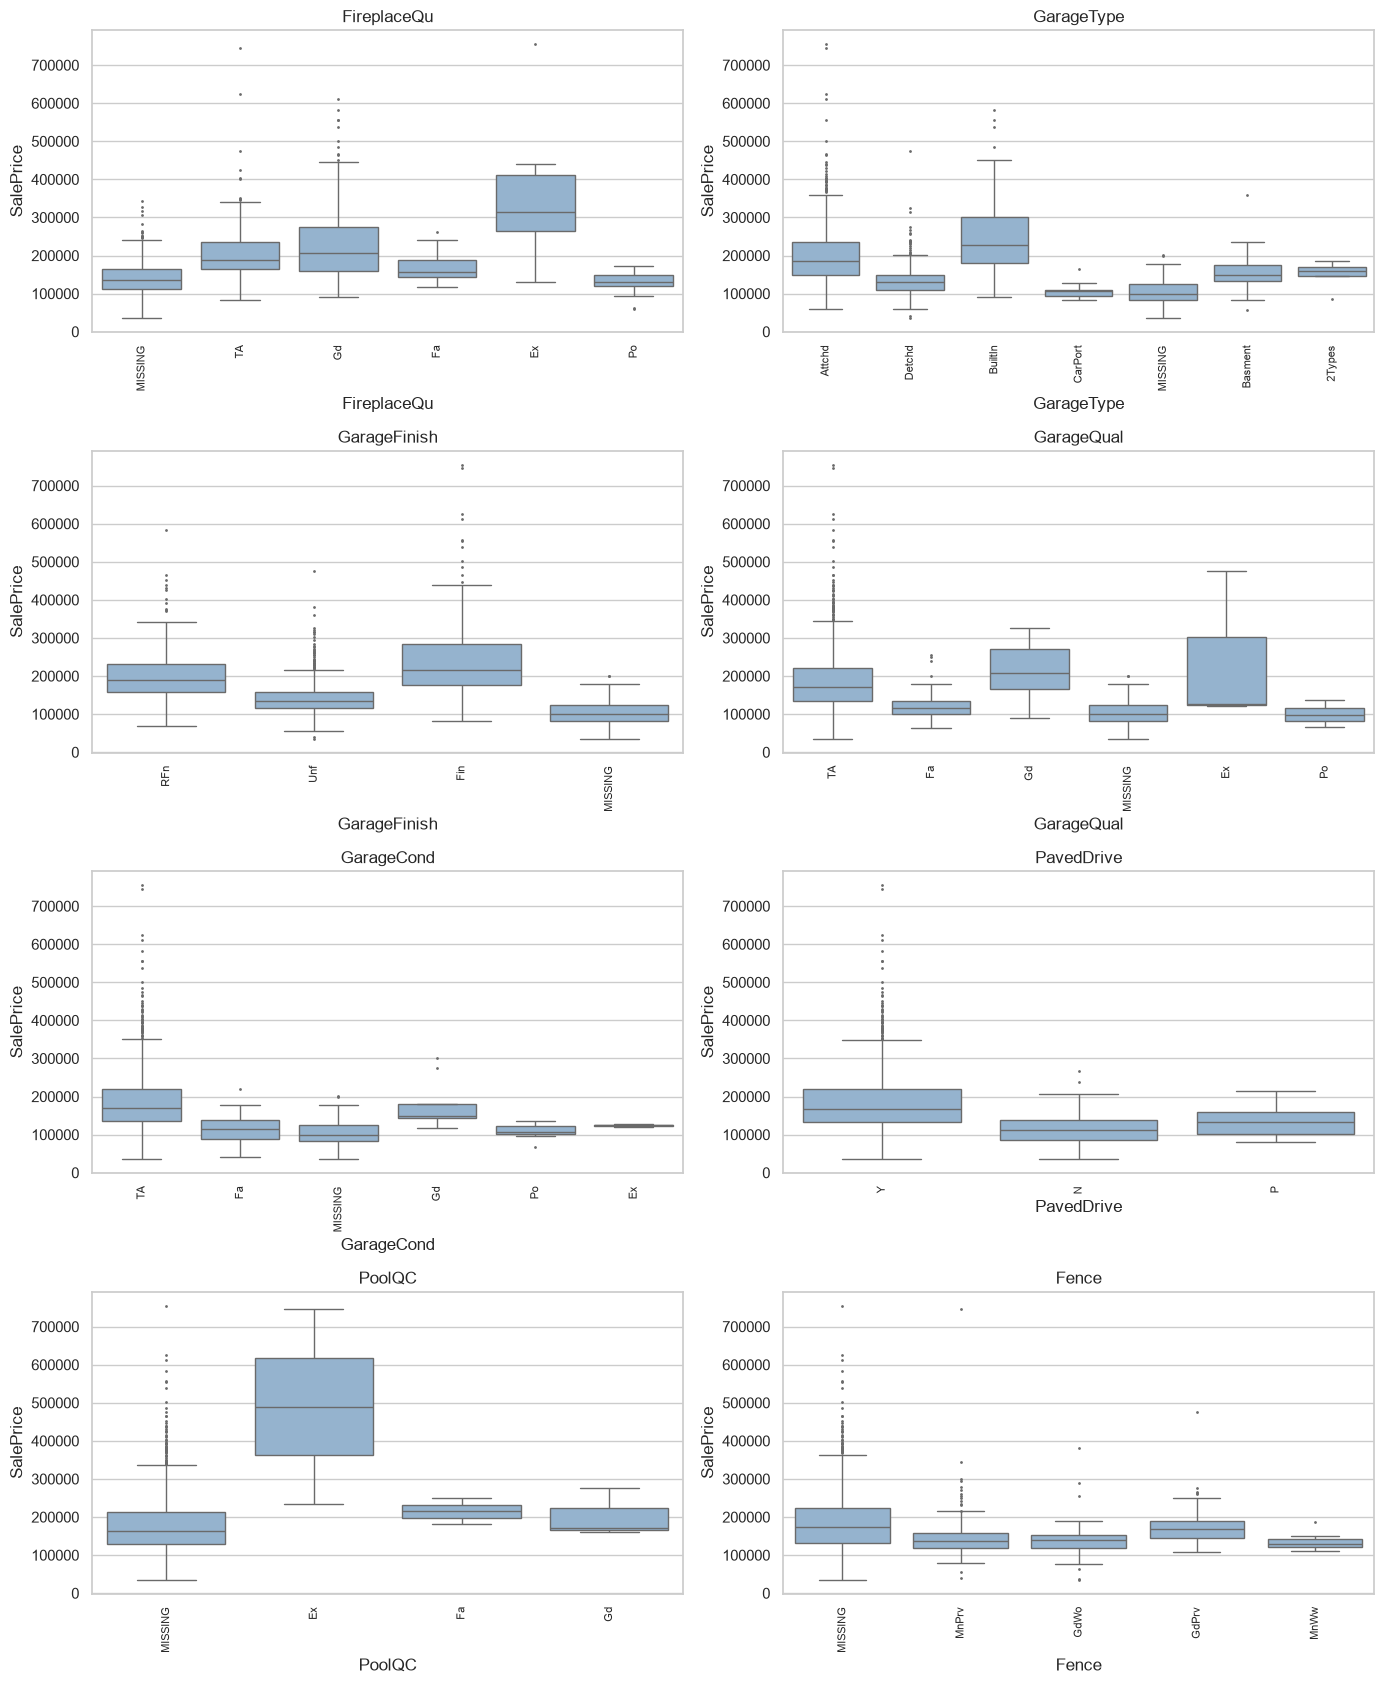

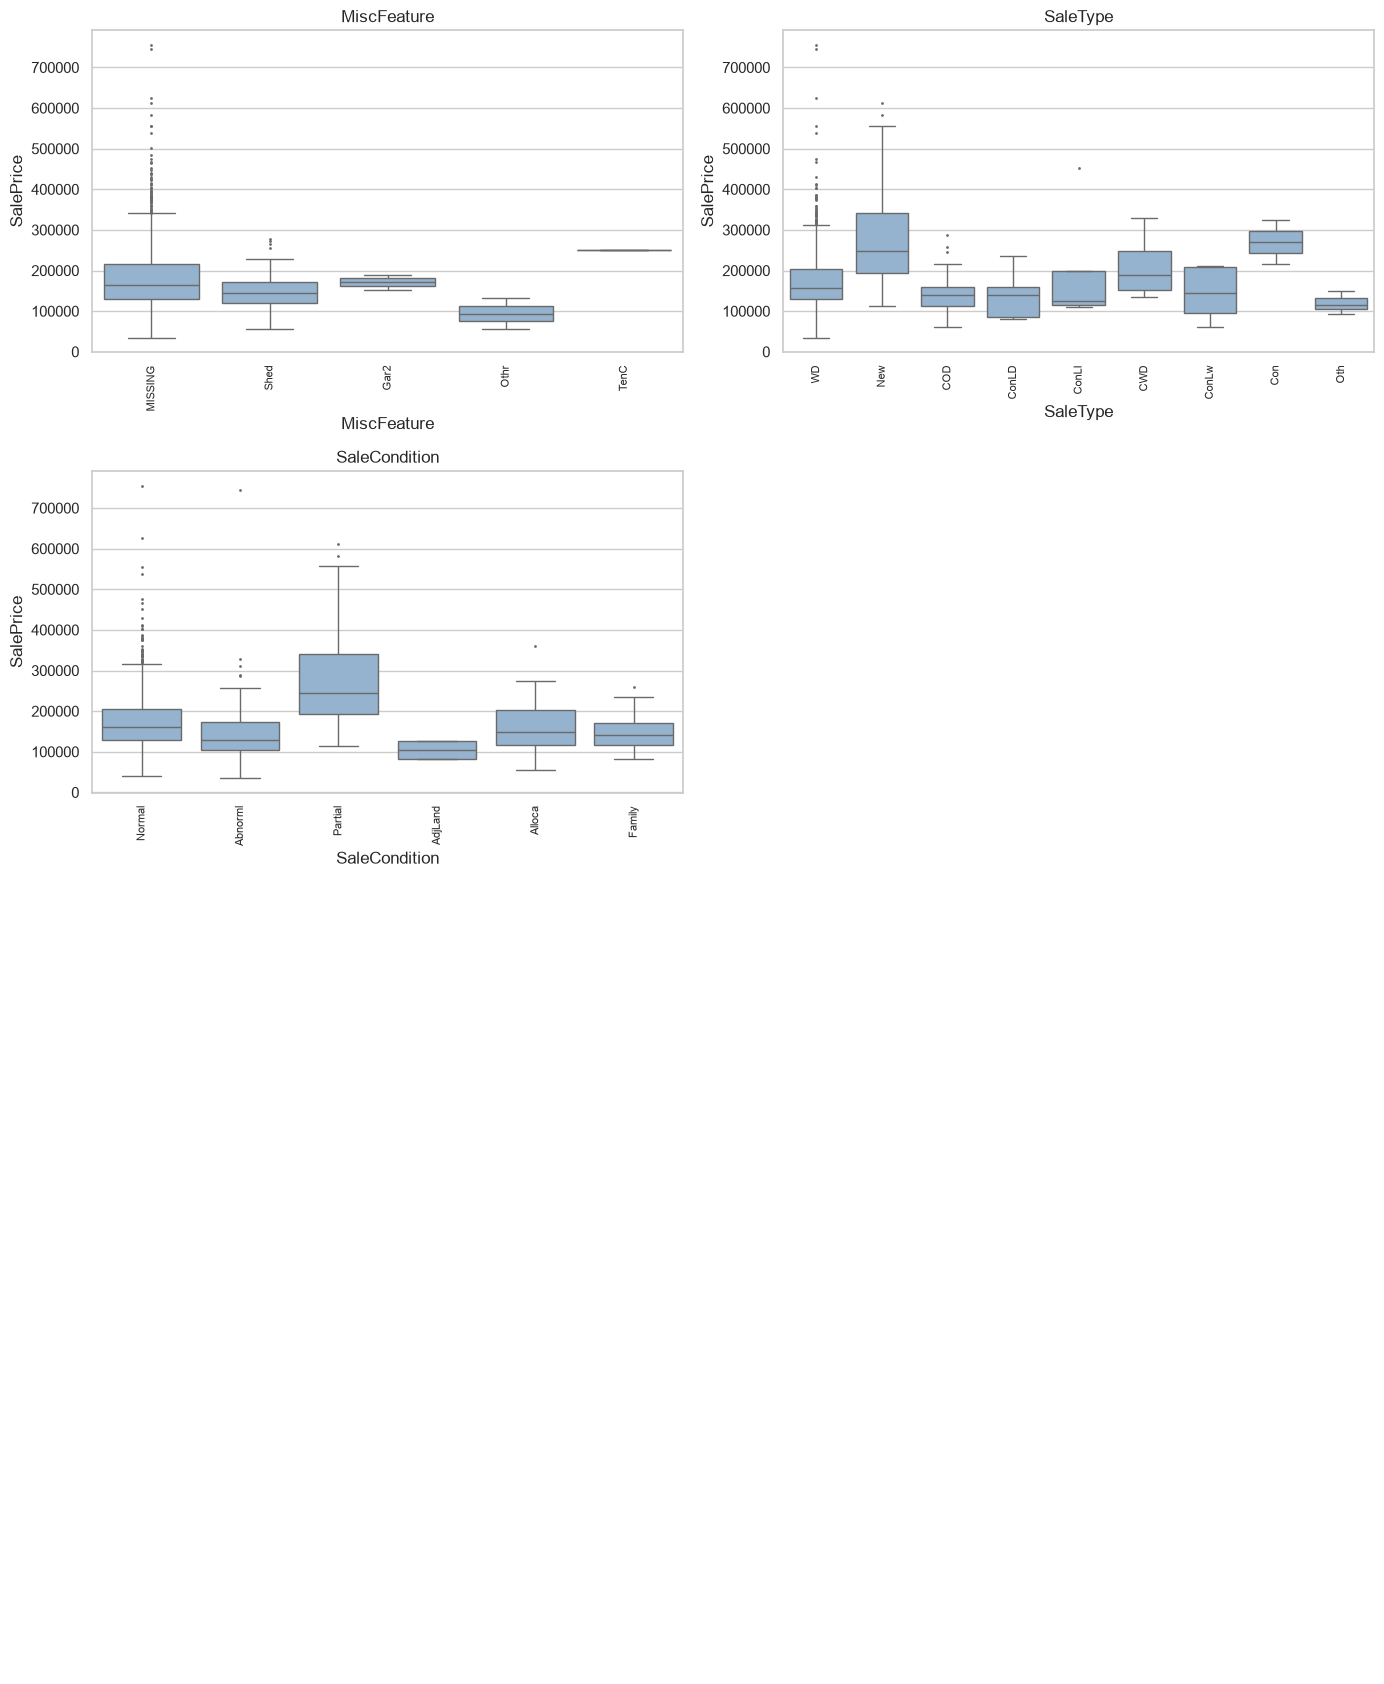

All categorical columns plotted: 43


In [30]:
# Plot all 43 category columns over several figures so each one stays readable.
plot_train=train.copy(deep=True)
for c in categorical_features.columns:
    plot_train[c]=plot_train[c].astype('string').fillna('MISSING')
cat_names=categorical_features.columns.tolist()
for start in range(0,len(cat_names),8):
    subset=cat_names[start:start+8]
    fig,axes=plt.subplots(4,2,figsize=(14,17)); axes=axes.ravel()
    for ax,c in zip(axes,subset):
        sns.boxplot(data=plot_train,x=c,y='SalePrice',ax=ax,color='#8bb4d8',fliersize=1)
        ax.tick_params(axis='x',rotation=90,labelsize=8); ax.set_title(c)
    for ax in list(axes)[len(subset):]: ax.axis('off')
    fig.tight_layout()
    fig.savefig(OUT/f'house_categories_page_{start//8+1:02d}.png',bbox_inches='tight')
    plt.show();plt.close(fig)
print('All categorical columns plotted:',len(cat_names))

#### Housing Price vs Sales

- Sale Type & Condition
- Sales Seasonality

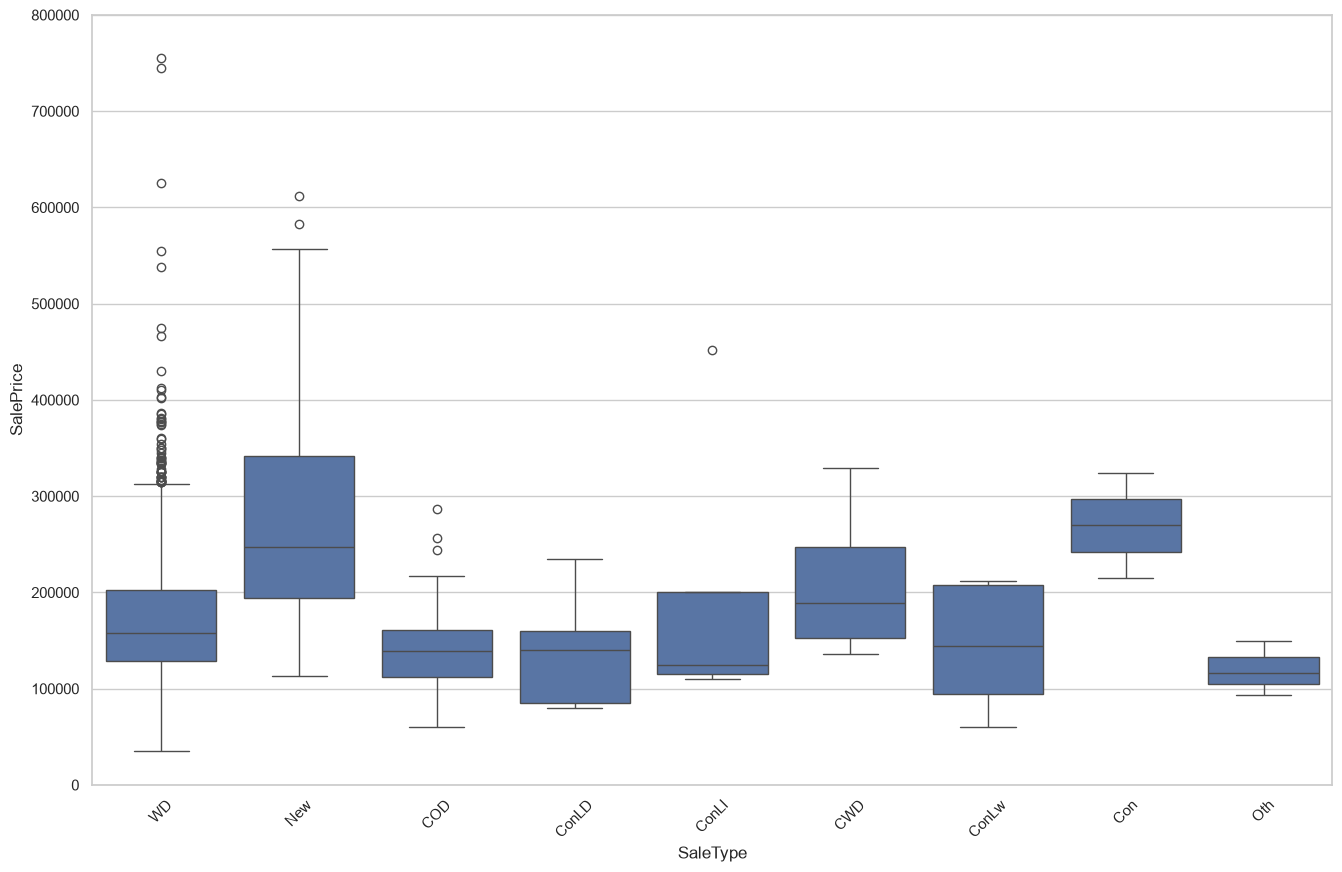

In [31]:
var = 'SaleType'
data = pd.concat([train['SalePrice'], train[var]], axis=1)
f, ax = plt.subplots(figsize=(16, 10))
fig = sns.boxplot(x=var, y="SalePrice", data=data)
fig.axis(ymin=0, ymax=800000);
xt = plt.xticks(rotation=45)
save_figures('house_cell_61')

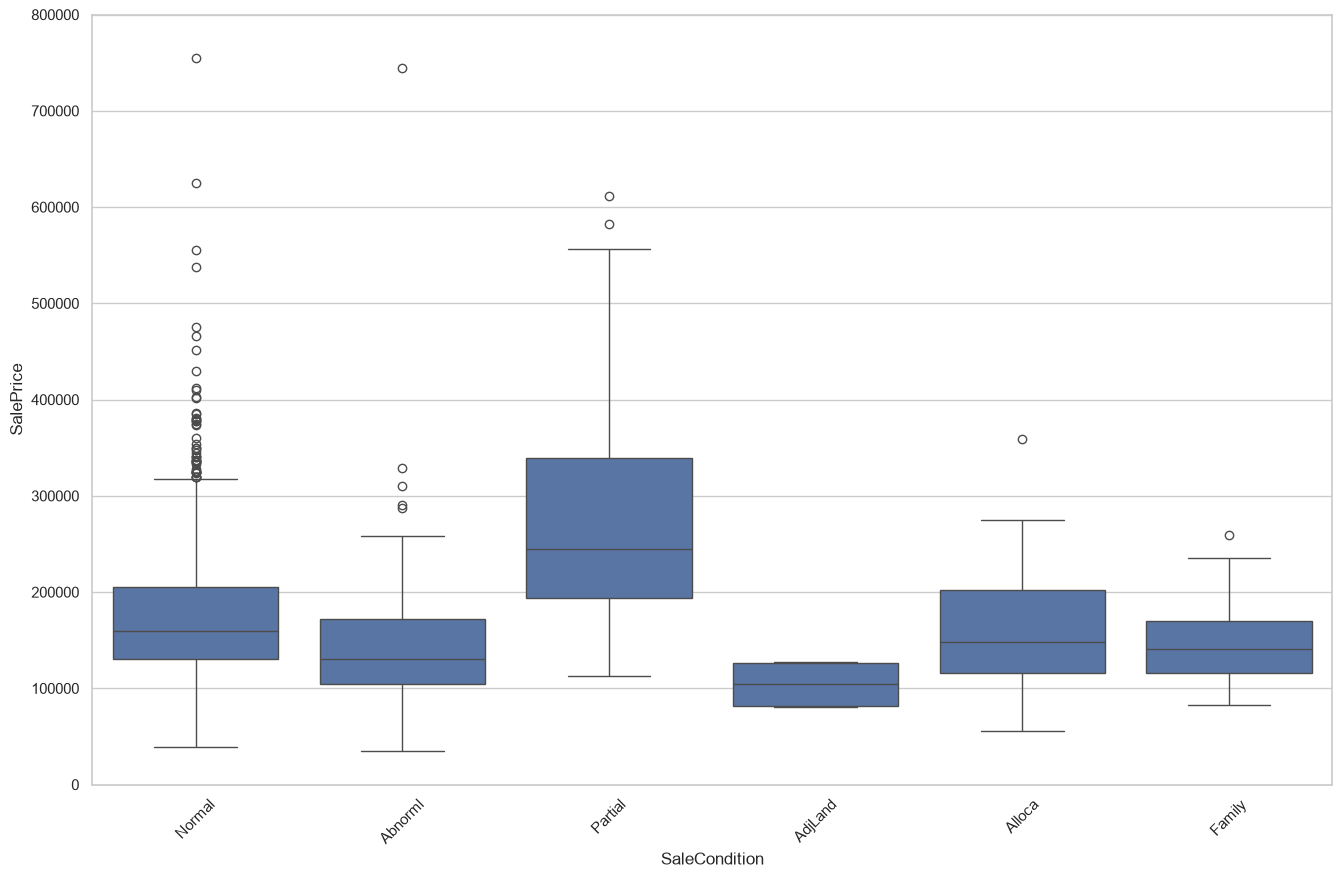

In [32]:
var = 'SaleCondition'

data = pd.concat([train['SalePrice'], train[var]], axis=1)

f, ax = plt.subplots(figsize=(16, 10))

fig = sns.boxplot(x=var, y="SalePrice", data=data)

fig.axis(ymin=0, ymax=800000);

xt = plt.xticks(rotation=45)
save_figures('house_cell_62')

#### ViolinPlot - Functional vs.SalePrice

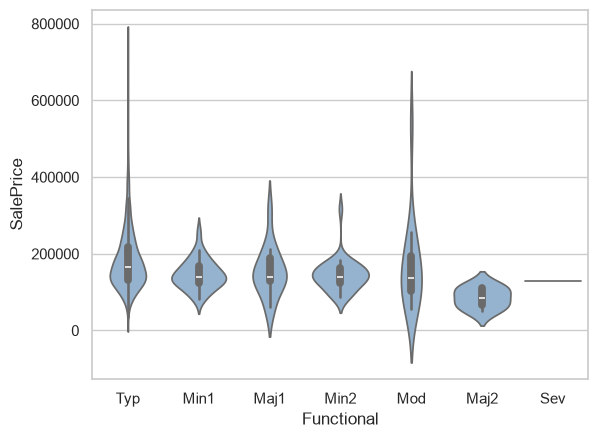

In [33]:
sns.violinplot(data=train,x='Functional',y='SalePrice',color='#8bb4d8')
save_figures('house_cell_64')

#### FactorPlot - FirePlaceQC vs. SalePrice 

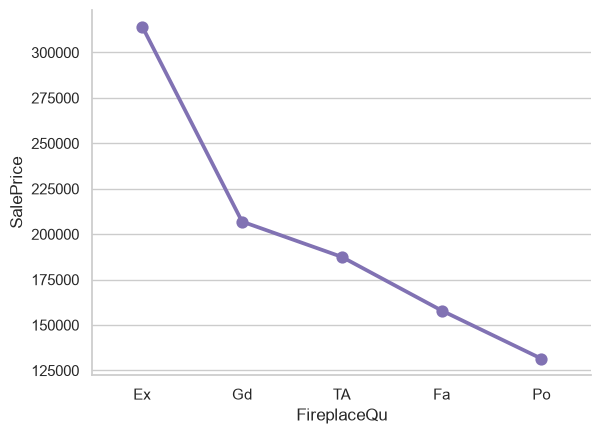

In [34]:
sns.catplot(data=train,x='FireplaceQu',y='SalePrice',kind='point',estimator='median',order=['Ex','Gd','TA','Fa','Po'],height=4.5,aspect=1.35,errorbar=None,color='m')
save_figures('house_cell_66')

#### Facet Grid Plot - FirePlace QC vs.SalePrice

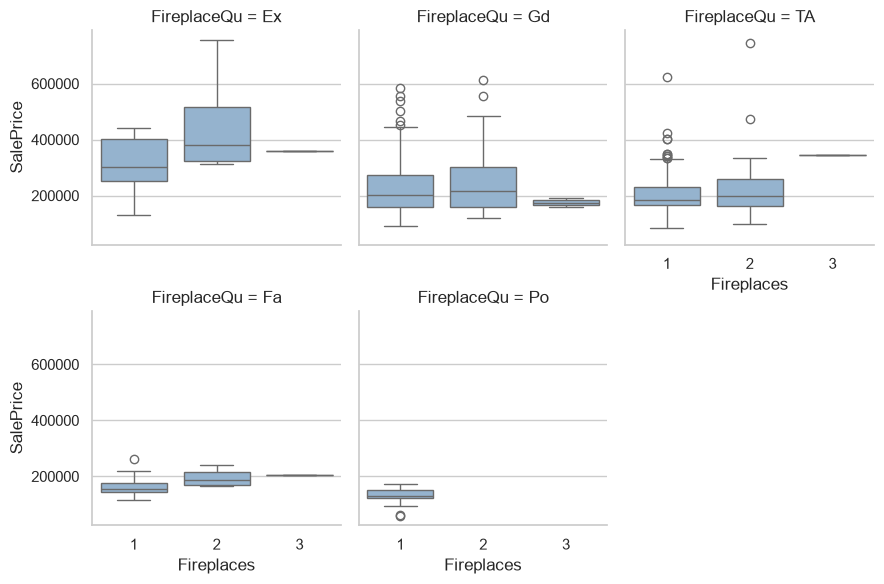

In [35]:
g=sns.FacetGrid(train,col='FireplaceQu',col_wrap=3,col_order=['Ex','Gd','TA','Fa','Po']);g.map_dataframe(sns.boxplot,x='Fireplaces',y='SalePrice',order=[1,2,3],color='#8bb4d8')
save_figures('house_cell_68')

#### PointPlot

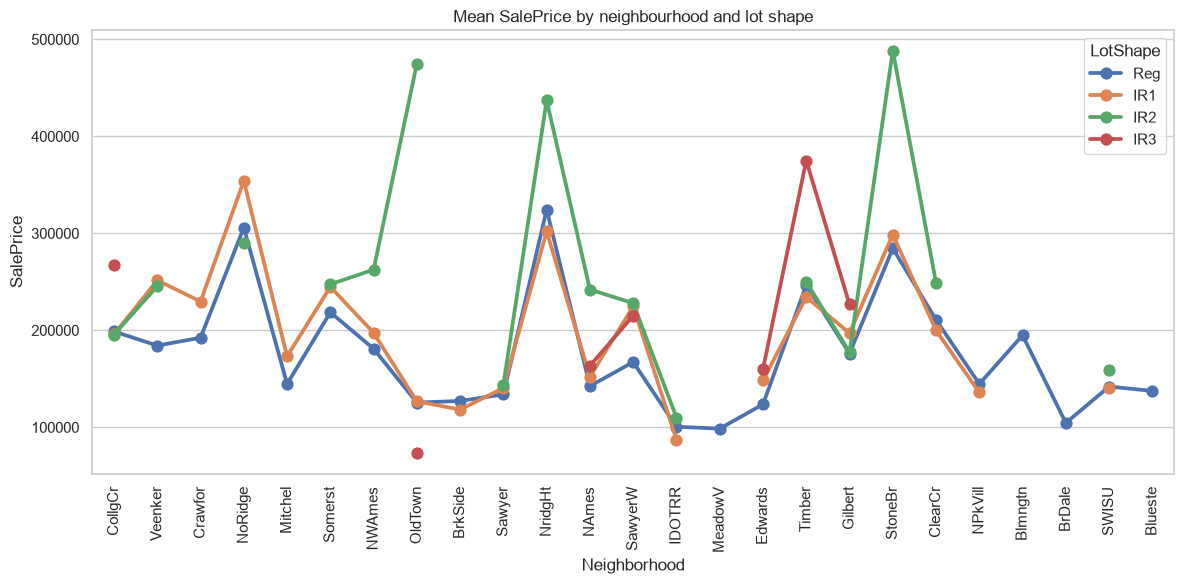

In [36]:
fig,ax=plt.subplots(figsize=(12,6));sns.pointplot(data=train,x='Neighborhood',y='SalePrice',hue='LotShape',errorbar=None,ax=ax);ax.tick_params(axis='x',rotation=90);ax.set(title='Mean SalePrice by neighbourhood and lot shape');fig.tight_layout()
save_figures('house_cell_70')

 ### Missing Value Analysis 
 
 #### Numeric Features

In [37]:
total = numeric_features.isnull().sum().sort_values(ascending=False)
percent = (numeric_features.isnull().sum()/numeric_features.isnull().count()*100).sort_values(ascending=False)
missing_data = pd.concat([total, percent], axis=1,join='outer', keys=['Total Missing Count', '% of Total Observations'])
missing_data.index.name =' Numeric Feature'

display(missing_data.head(20))

,Total Missing Count,% of Total Observations
Numeric Feature,,
LotFrontage,259,17.739726
GarageYrBlt,81,5.547945
MasVnrArea,8,0.547945
LotArea,0,0.000000
MSSubClass,0,0.000000
Id,0,0.000000
OverallCond,0,0.000000
OverallQual,0,0.000000
YearRemodAdd,0,0.000000


#### Missing values for all numeric features in Bar chart Representation

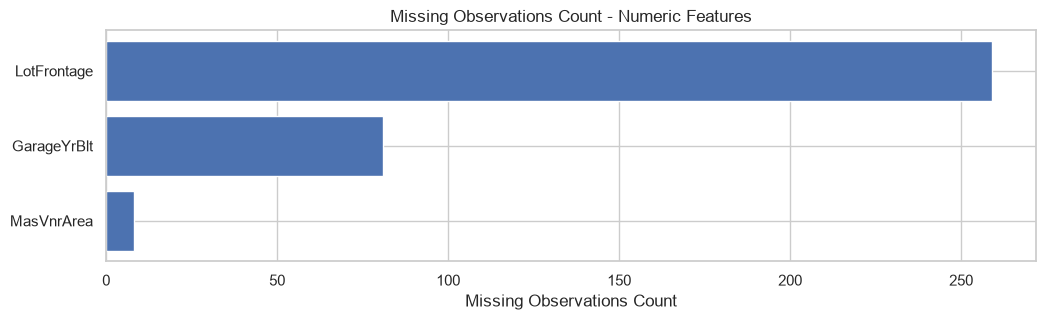

In [38]:
missing_values = numeric_features.isnull().sum(axis=0).reset_index()
missing_values.columns = ['column_name', 'missing_count']
missing_values = missing_values.loc[missing_values['missing_count']>0]
missing_values = missing_values.sort_values(by='missing_count')

ind = np.arange(missing_values.shape[0])
width = 0.1
fig, ax = plt.subplots(figsize=(12,3))
rects = ax.barh(ind, missing_values.missing_count.values, color='b')
ax.set_yticks(ind)
ax.set_yticklabels(missing_values.column_name.values, rotation='horizontal')
ax.set_xlabel("Missing Observations Count")
ax.set_title("Missing Observations Count - Numeric Features")
None

save_figures('house_cell_74')

#### Categorical Features

In [39]:
total = categorical_features.isnull().sum().sort_values(ascending=False)
percent = (categorical_features.isnull().sum()/categorical_features.isnull().count()*100).sort_values(ascending=False)
missing_data = pd.concat([total, percent], axis=1,join='outer', keys=['Total Missing Count', ' % of Total Observations'])
missing_data.index.name ='Feature'
display(missing_data.head(20))

,Total Missing Count,% of Total Observations
Feature,,
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
GarageFinish,81,5.547945
GarageQual,81,5.547945
GarageType,81,5.547945


#### Missing values for  Categorical features in Bar chart Representation

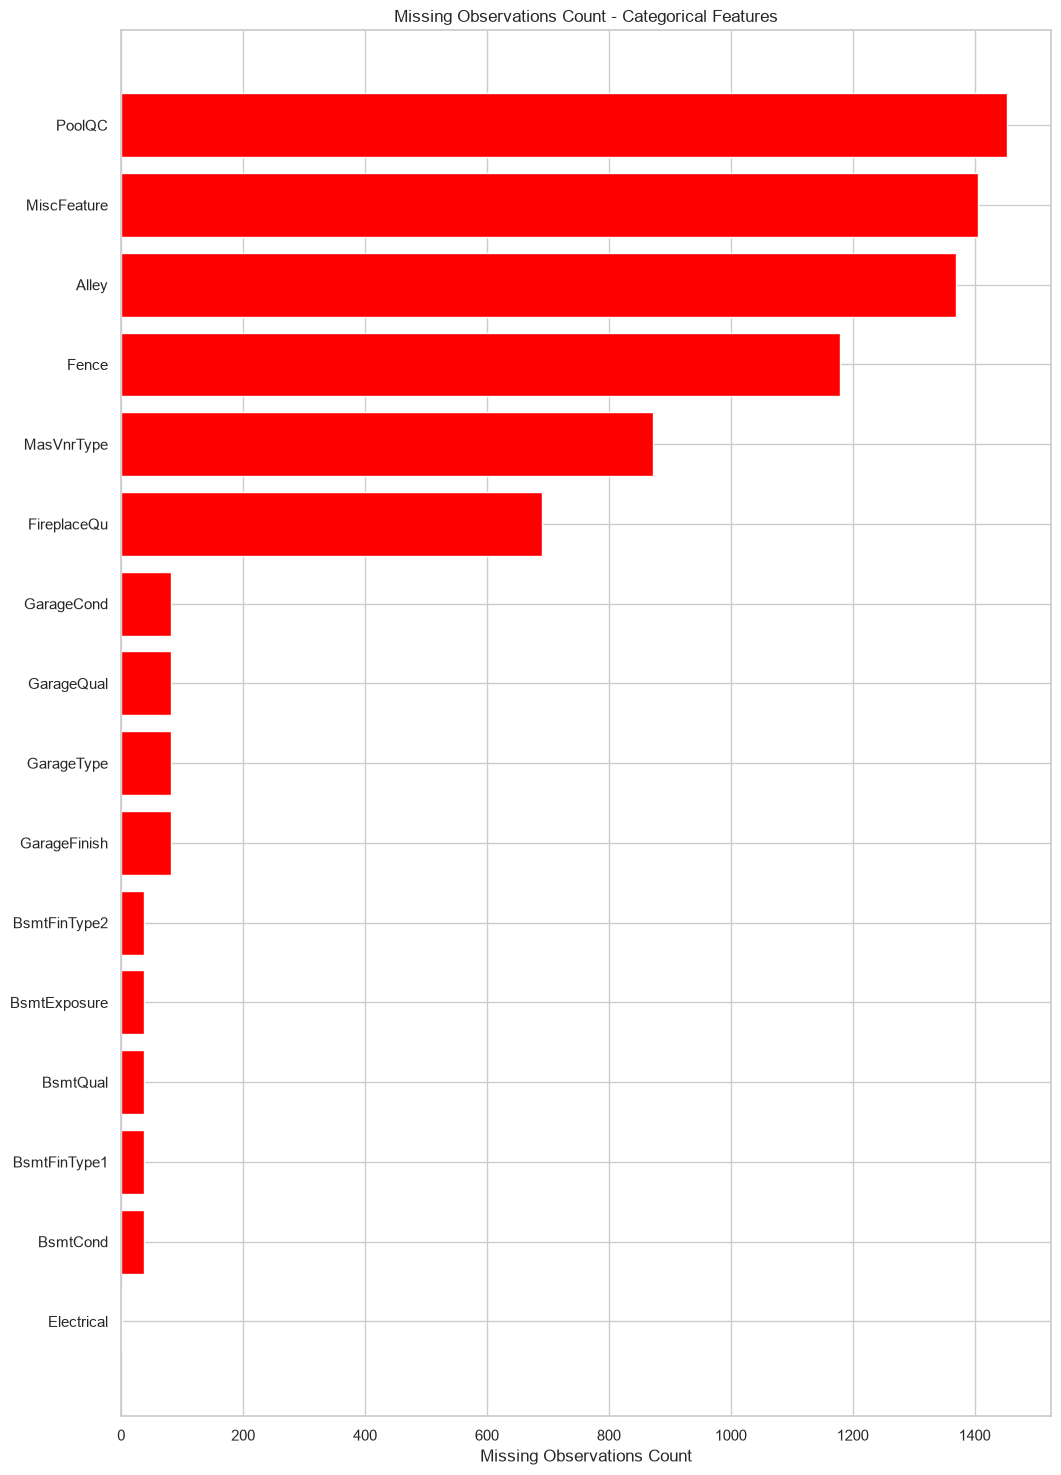

In [40]:
missing_values = categorical_features.isnull().sum(axis=0).reset_index()
missing_values.columns = ['column_name', 'missing_count']
missing_values = missing_values.loc[missing_values['missing_count']>0]
missing_values = missing_values.sort_values(by='missing_count')

ind = np.arange(missing_values.shape[0])
width = 0.9
fig, ax = plt.subplots(figsize=(12,18))
rects = ax.barh(ind, missing_values.missing_count.values, color='red')
ax.set_yticks(ind)
ax.set_yticklabels(missing_values.column_name.values, rotation='horizontal')
ax.set_xlabel("Missing Observations Count")
ax.set_title("Missing Observations Count - Categorical Features")
None
save_figures('house_cell_78')

### Categorical Feature Exploration

In [41]:
# Example only: fill gaps in both copies with the most common training value, never a test value.
# A gap here can mean the house has no such feature, so real modelling would need a closer look.
train_demo=train_raw.copy(deep=True);test_demo=test_raw.copy(deep=True)
for c in categorical_features.columns:
    modes=train_raw[c].mode(dropna=True)
    fill=modes.iloc[0] if len(modes) else 'MISSING'
    train_demo[c]=train_demo[c].fillna(fill)
    test_demo[c]=test_demo[c].fillna(fill)
assert train.equals(train_raw) and test.equals(test_raw)
print('Raw tables preserved. Demonstration fills were learned from training only.')

Raw tables preserved. Demonstration fills were learned from training only.


### Housing checks and summary
I explored the training data only. The test file has no prices, so it cannot measure prediction error. Taking the log of SalePrice reduced its skew (its long tail to the right), but that alone does not show that a model would work. The missing-value heatmap shows which columns tend to be empty together; it is not a correlation between the values themselves.

In [42]:
house_missing=pd.DataFrame({'train_count':train_raw.isna().sum(),'train_percent':100*train_raw.isna().mean(),'test_count':test_raw.isna().sum()}).sort_values('train_count',ascending=False)
house_missing.to_csv(OUT/'house_missingness.csv')
house_corr=numeric_features.drop(columns=['Id']).corr()['SalePrice'].drop('SalePrice').sort_values(ascending=False)
house_corr.to_csv(OUT/'house_target_correlations.csv')
house_summary={'training_rows':len(train),'test_rows':len(test),'train_columns':len(train.columns),'test_columns':len(test.columns),'saleprice_skew':float(train.SalePrice.skew()),'saleprice_excess_kurtosis':float(train.SalePrice.kurt()),'log_saleprice_skew':float(np.log(train.SalePrice).skew()),'quality_price_r':float(train.OverallQual.corr(train.SalePrice))}
assert np.isclose(house_summary['saleprice_skew'],1.8828757597682118)
assert train.equals(train_raw) and test.equals(test_raw)
display(house_missing.head(10));print(house_summary)
print('PASS: complete corrected housing tutorial and input-preservation checks.')

,train_count,train_percent,test_count
PoolQC,1453,99.520548,1456.0
MiscFeature,1406,96.301370,1408.0
Alley,1369,93.767123,1352.0
Fence,1179,80.753425,1169.0
MasVnrType,872,59.726027,894.0
FireplaceQu,690,47.260274,730.0
LotFrontage,259,17.739726,227.0
GarageYrBlt,81,5.547945,78.0
GarageFinish,81,5.547945,78.0
GarageQual,81,5.547945,78.0


{'training_rows': 1460, 'test_rows': 1459, 'train_columns': 81, 'test_columns': 80, 'saleprice_skew': 1.8828757597682118, 'saleprice_excess_kurtosis': 6.536281860064525, 'log_saleprice_skew': 0.1213350622052098, 'quality_price_r': 0.790981600583805}
PASS: complete corrected housing tutorial and input-preservation checks.


## Part B: the Auto MPG tasks
The file has 398 rows and 9 columns. Horsepower uses `?` for six missing values. Origin is stored as a number (1 = America, 2 = Europe, 3 = Japan), but the numbers name groups and do not measure anything, so I kept origin out of the correlations. Car names identify models only. The cars date from 1970 to 1982, so they say nothing about the performance of cars today.

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino


,Missing count,Percent,Available n
mpg,0,0.000000,398
cylinders,0,0.000000,398
displacement,0,0.000000,398
horsepower,6,1.507538,392
weight,0,0.000000,398
acceleration,0,0.000000,398
model year,0,0.000000,398
origin,0,0.000000,398
car name,0,0.000000,398


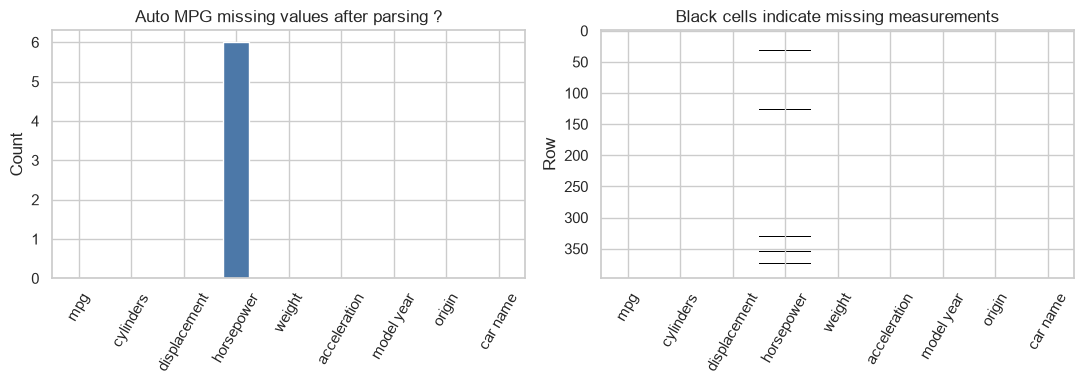

In [43]:
auto_raw=pd.read_csv('Auto-mpg dataset.csv',keep_default_na=False)
auto=auto_raw.copy(deep=True)
auto['horsepower']=pd.to_numeric(auto['horsepower'].replace('?',np.nan),errors='raise')
for c in ['mpg','cylinders','displacement','weight','acceleration','model year','origin']:
    auto[c]=pd.to_numeric(auto[c],errors='raise')
assert auto.shape==(398,9)
assert auto_raw['horsepower'].eq('?').sum()==6
assert auto.isna().sum().sum()==6 and auto.horsepower.isna().sum()==6
auto_missing=pd.DataFrame({'Missing count':auto.isna().sum(),'Percent':100*auto.isna().mean(),'Available n':auto.notna().sum()})
display(auto.head());display(auto_missing)
auto_missing.to_csv(OUT/'auto_missingness.csv')
fig,axes=plt.subplots(1,2,figsize=(11,4));auto_missing['Missing count'].plot.bar(ax=axes[0],color='#4c78a8');axes[0].set(title='Auto MPG missing values after parsing ?',ylabel='Count');axes[0].tick_params(axis='x',rotation=60)
axes[1].imshow(auto.isna().to_numpy(),aspect='auto',interpolation='nearest',cmap='Greys');axes[1].set(xticks=range(9),xticklabels=auto.columns,ylabel='Row',title='Black cells indicate missing measurements');axes[1].tick_params(axis='x',rotation=60)
fig.tight_layout();save_figures('auto_01_missingness')

### Skewness and excess kurtosis
I used only the values present and did not fill the six missing horsepower values. Skewness shows whether a column has a longer tail on one side; a positive value means a longer tail to the right. Excess kurtosis compares the tails with a normal distribution, which scores 0. A negative score alone is not a reason to transform a column. Cylinders and model year take only a few whole-number values, so I report them without treating them as normally distributed. I left out origin and car name, because the skewness of group labels has no meaning.

,Available n,Skewness,Excess kurtosis
mpg,398,0.4571,-0.5108
cylinders,398,0.5269,-1.3767
displacement,398,0.7196,-0.7466
horsepower,392,1.0873,0.6969
weight,398,0.5311,-0.7855
acceleration,398,0.2788,0.4195
model year,398,0.0115,-1.1812


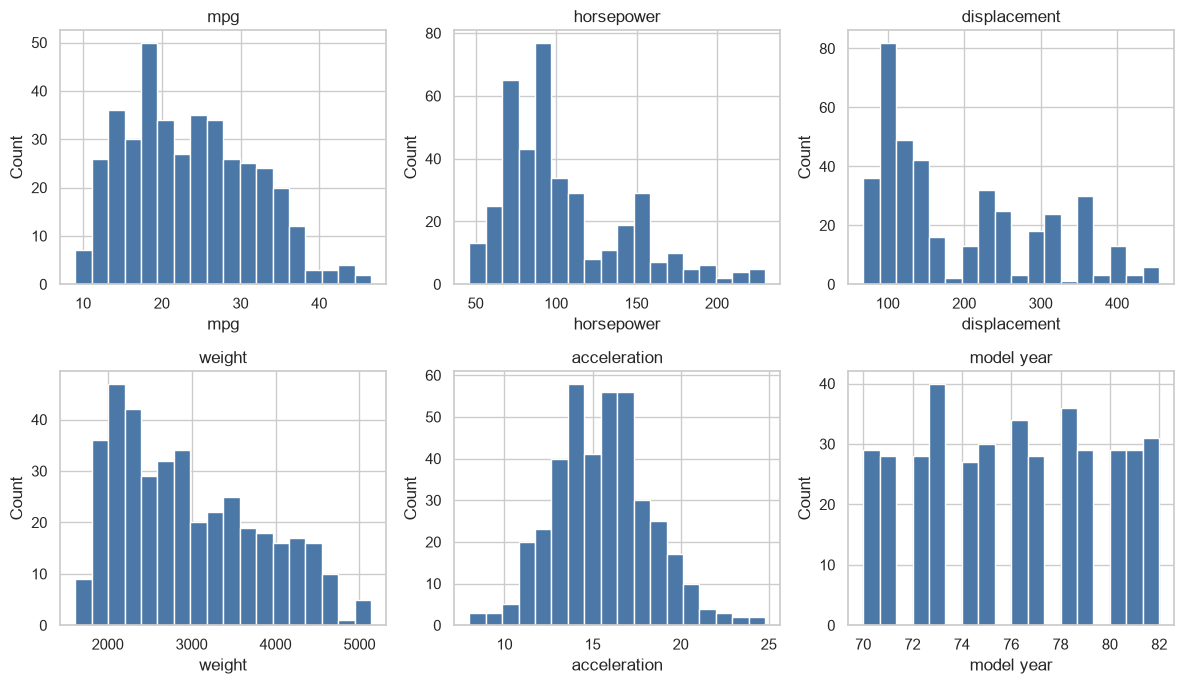

In [44]:
auto_features=['mpg','cylinders','displacement','horsepower','weight','acceleration','model year']
auto_moments=pd.DataFrame({'Available n':auto[auto_features].count(),'Skewness':auto[auto_features].skew(),'Excess kurtosis':auto[auto_features].kurt()})
display(auto_moments.round(4));auto_moments.to_csv(OUT/'auto_moments.csv')
fig,axes=plt.subplots(2,3,figsize=(12,7))
for ax,c in zip(axes.flat,['mpg','horsepower','displacement','weight','acceleration','model year']):
    ax.hist(auto[c].dropna(),bins=18,color='#4c78a8',edgecolor='white');ax.set(title=c,xlabel=c,ylabel='Count')
fig.tight_layout();save_figures('auto_02_distributions')

### Correlation heatmap and sample counts
Each correlation uses every row where both values are present. Pairs with horsepower have 392 rows; the others have 398. I saved the counts alongside the correlations so the difference is visible. A correlation does not show cause: weight, displacement and horsepower rise together, and these are observed cars, not an experiment.

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year
mpg,1.0000,-0.7754,-0.8042,-0.7784,-0.8317,0.4203,0.5793
cylinders,-0.7754,1.0000,0.9507,0.8430,0.8960,-0.5054,-0.3487
displacement,-0.8042,0.9507,1.0000,0.8973,0.9328,-0.5437,-0.3702
horsepower,-0.7784,0.8430,0.8973,1.0000,0.8645,-0.6892,-0.4164
weight,-0.8317,0.8960,0.9328,0.8645,1.0000,-0.4175,-0.3066
acceleration,0.4203,-0.5054,-0.5437,-0.6892,-0.4175,1.0000,0.2881
model year,0.5793,-0.3487,-0.3702,-0.4164,-0.3066,0.2881,1.0000


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year
mpg,398,398,398,392,398,398,398
cylinders,398,398,398,392,398,398,398
displacement,398,398,398,392,398,398,398
horsepower,392,392,392,392,392,392,392
weight,398,398,398,392,398,398,398
acceleration,398,398,398,392,398,398,398
model year,398,398,398,392,398,398,398


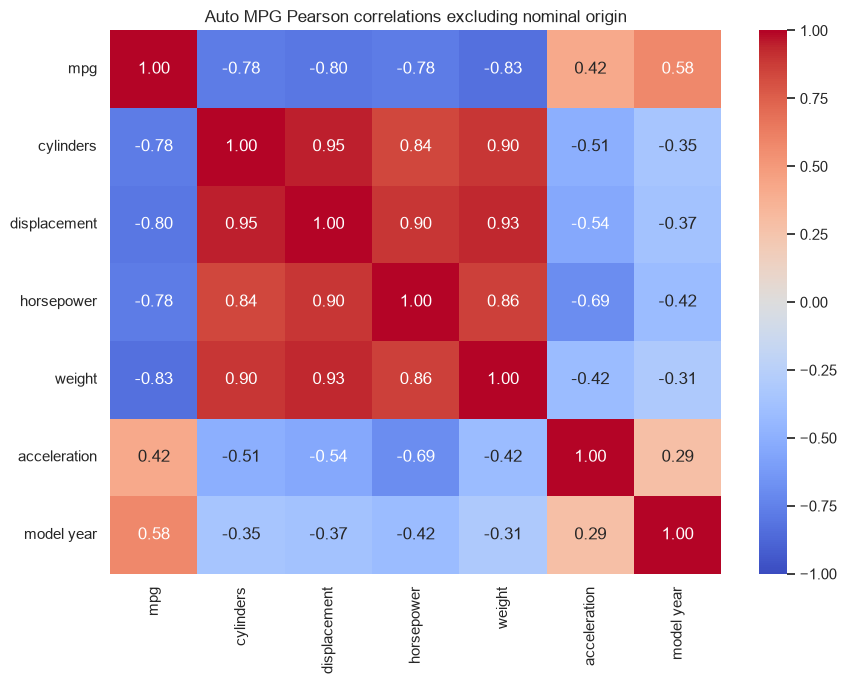

In [45]:
auto_corr=auto[auto_features].corr()
auto_pair_n=auto[auto_features].notna().astype(int).T.dot(auto[auto_features].notna().astype(int))
auto_corr.to_csv(OUT/'auto_correlations.csv');auto_pair_n.to_csv(OUT/'auto_correlation_pair_counts.csv')
display(auto_corr.round(4));display(auto_pair_n)
fig,ax=plt.subplots(figsize=(9,7));sns.heatmap(auto_corr,annot=True,fmt='.2f',vmin=-1,vmax=1,center=0,cmap='coolwarm',ax=ax);ax.set_title('Auto MPG Pearson correlations excluding nominal origin');fig.tight_layout();save_figures('auto_03_heatmap')

### Scatter plots for each input
Each plot shows one input against mpg. The red line is a visual guide only, not a tested forecast. Colour shows origin. A single correlation can miss a curve, or a spread that widens, which is why I also checked the plots. I removed no points simply because they looked unusual.

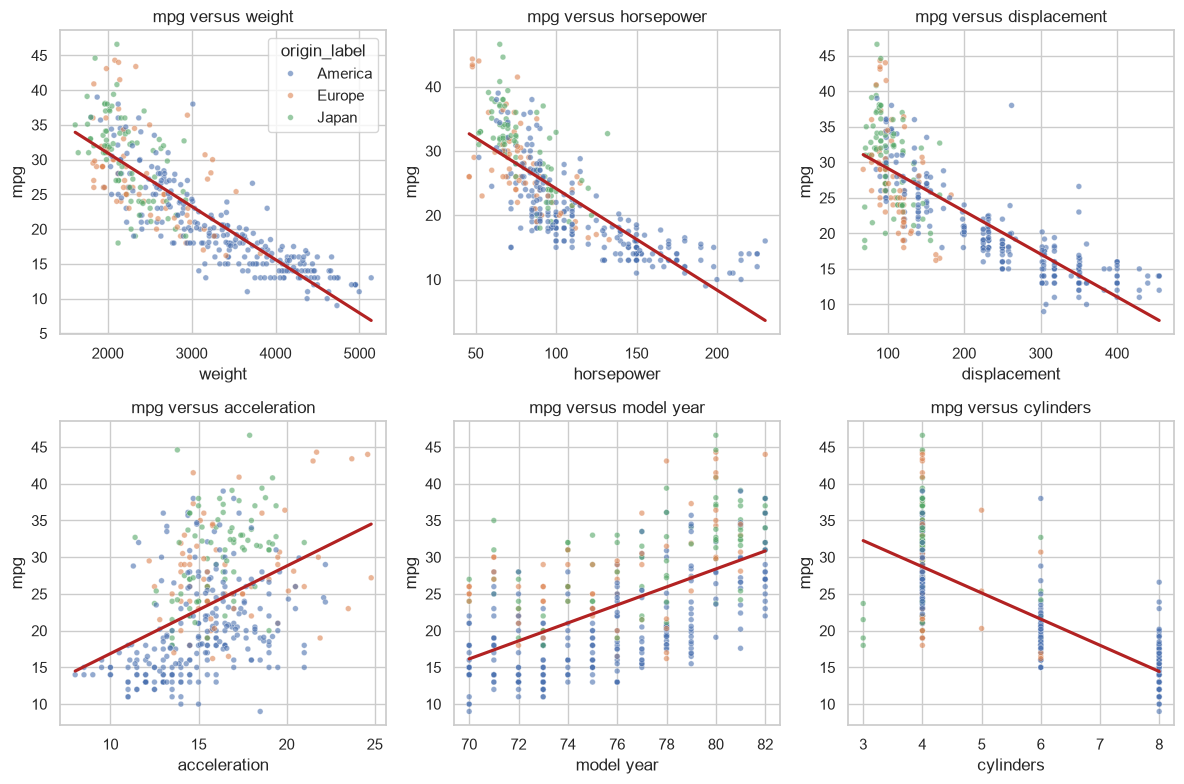

In [46]:
origin_names={1:'America',2:'Europe',3:'Japan'}
auto['origin_label']=auto.origin.map(origin_names)
assert not auto.origin_label.isna().any()
fig,axes=plt.subplots(2,3,figsize=(12,8))
for ax,c in zip(axes.flat,['weight','horsepower','displacement','acceleration','model year','cylinders']):
    sns.scatterplot(data=auto,x=c,y='mpg',hue='origin_label',hue_order=['America','Europe','Japan'],s=17,alpha=.6,ax=ax,legend=(c=='weight'))
    sns.regplot(data=auto,x=c,y='mpg',scatter=False,ci=None,color='firebrick',ax=ax)
    ax.set_title(f'mpg versus {c}')
fig.tight_layout();save_figures('auto_04_scatterplots')

### Category labels and numerical encoding
Origin arrives as numbers. I turned them back into names, mapped them to 1, 2 and 3 again, and checked that this reproduced the original codes. I also made one column per origin (one-hot encoding: a 1 in the car's own column and 0 in the others). Without this, a method that reads numbers as distances would place Europe halfway between America and Japan. The mpg summaries by origin describe these cars only; they do not show that origin causes the difference.

,origin_label,origin_encoded
0,America,1
19,Europe,2
14,Japan,3


,origin_America,origin_Europe,origin_Japan
0,1,0,0
1,1,0,0
2,1,0,0
3,1,0,0
4,1,0,0


,n,mean_mpg,median_mpg
origin_label,,,
America,249,20.084,18.5
Europe,70,27.891,26.5
Japan,79,30.451,31.6


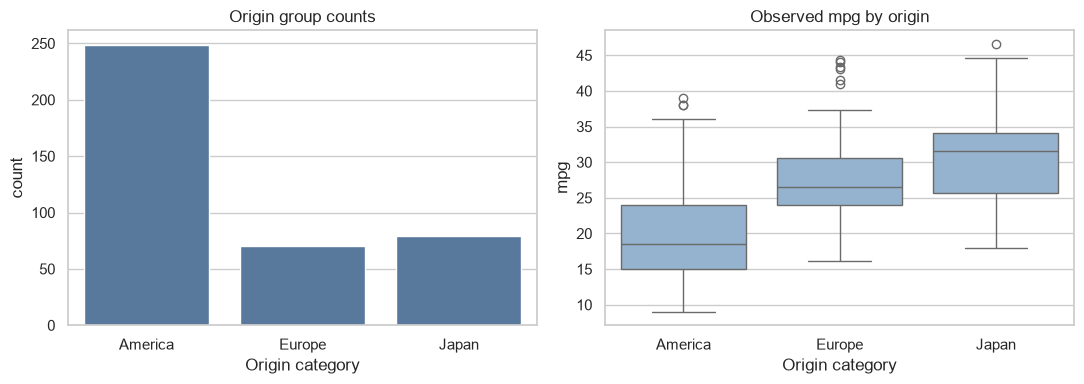

In [47]:
origin_to_code={'America':1,'Europe':2,'Japan':3}
auto['origin_encoded']=auto.origin_label.map(origin_to_code)
assert auto.origin_encoded.equals(auto.origin)
one_hot=pd.get_dummies(auto.origin_label,prefix='origin',dtype=int)
assert one_hot.sum(axis=1).eq(1).all()
auto_encoded=pd.concat([auto.drop(columns=['origin','origin_label','origin_encoded','car name']),one_hot],axis=1)
display(auto[['origin_label','origin_encoded']].drop_duplicates().sort_values('origin_encoded'))
display(one_hot.head())
auto_group=auto.groupby('origin_label',observed=True).agg(n=('mpg','size'),mean_mpg=('mpg','mean'),median_mpg=('mpg','median'))
display(auto_group.round(3));auto_group.to_csv(OUT/'auto_origin_summary.csv')
auto_encoded.to_csv(OUT/'auto_one_hot_encoded.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4))
sns.countplot(data=auto,x='origin_label',order=['America','Europe','Japan'],color='#4c78a8',ax=axes[0]);axes[0].set(title='Origin group counts',xlabel='Origin category')
sns.boxplot(data=auto,x='origin_label',y='mpg',order=['America','Europe','Japan'],color='#8bb4d8',ax=axes[1]);axes[1].set(title='Observed mpg by origin',xlabel='Origin category')
fig.tight_layout();save_figures('auto_05_encoding_groups')

### Missing values: a sensitivity check
My main results use the data as loaded. As an illustration only, I compared the horsepower and mpg correlation on the 392 complete rows with a copy where the six gaps hold the median, 93.5. Filling with the median makes those cars appear more alike than they are, and it does not reveal their true values. The brief asks for no model. If I built one later, I would split the data first and learn any filling from the training part only, because this exploration has already seen every row.

In [48]:
auto_median=auto.horsepower.median()
auto_demo=auto.copy(deep=True);auto_demo['horsepower']=auto_demo.horsepower.fillna(auto_median)
auto_sensitivity=pd.DataFrame({'Treatment':['Available pairs','Median-filled demonstration'],'n':[auto.horsepower.notna().sum(),len(auto)],'horsepower_mpg_r':[auto.horsepower.corr(auto.mpg),auto_demo.horsepower.corr(auto_demo.mpg)]})
display(auto_sensitivity.round(5));auto_sensitivity.to_csv(OUT/'auto_missingness_sensitivity.csv',index=False)
assert np.isclose(auto_corr.loc['mpg','weight'],-0.831740933244335)
assert np.isclose(auto_moments.loc['mpg','Skewness'],0.457066343994919)
assert auto.origin.value_counts().to_dict()=={1:249,3:79,2:70}
assert auto['model year'].min()==70 and auto['model year'].max()==82
summary={'housing':house_summary,'auto':{'rows':len(auto),'horsepower_missing':int(auto.horsepower.isna().sum()),'horsepower_available_n':int(auto.horsepower.notna().sum()),'mpg_skew':float(auto.mpg.skew()),'mpg_excess_kurtosis':float(auto.mpg.kurt()),'horsepower_median':float(auto_median),'weight_mpg_r':float(auto_corr.loc['mpg','weight']),'horsepower_mpg_r':float(auto_corr.loc['mpg','horsepower']),'displacement_mpg_r':float(auto_corr.loc['mpg','displacement']),'weight_displacement_r':float(auto_corr.loc['weight','displacement']),'origin_counts':{str(k):int(v) for k,v in auto.origin.value_counts().items()}}}
(OUT/'Unit2_results_summary.json').write_text(json.dumps(summary,indent=2))
assert all(hashlib.sha256(Path(f).read_bytes()).hexdigest()==hashes[f] for f in required)
print('PASS: housing tutorial, all five Auto MPG tasks, encoding and input preservation checks.')
print('Results and figures saved to',str(OUT))

,Treatment,n,horsepower_mpg_r
0,Available pairs,392,-0.77843
1,Median-filled demonstration,398,-0.77345


PASS: housing tutorial, all five Auto MPG tasks, encoding and input preservation checks.
Results and figures saved to Unit2_ePortfolio_Exports


## Interpretation
Whether a dataset suits a method depends on its gaps, the shape of each column, the number of rows behind each correlation and how categories are coded, so I recorded all four. The origin codes must not be read as a ranking. Old car data cannot show how cars perform today, and they say nothing about fairness between people. In the housing data, the neighbourhood column could act as a proxy (an indirect stand-in) for the people who live there if it were used in real pricing decisions; I did not test this. UCI requires Auto MPG to be credited to Quinlan (1993). I kept the raw files unchanged so the work can be repeated.

## Sources
- De Cock, D. (2011) 'Ames, Iowa: alternative to the Boston Housing Data as an end of semester regression project', *Journal of Statistics Education*, 19(3). Available at: https://doi.org/10.1080/10691898.2011.11889627
- Géron, A. (2025) *Hands-On Machine Learning with Scikit-Learn and PyTorch*. Santa Rosa: O’Reilly.
- Quinlan, R. (1993) *Auto MPG* [Dataset]. UCI Machine Learning Repository. Available at: https://doi.org/10.24432/C5859H

Supplied materials: University of Essex Online Unit 2 seminar brief and the EDA tutorial notebook it sets, *A Tutorial on Exploratory Data Analysis*.